# 📈 Where Is the Money Really Flowing?
### Liquidity, Investor Conviction and Sector Performance in Indian Equities — NSE data, October 2026

**Final Project — Data Analytics using Python** &nbsp;|&nbsp; Pandas · NumPy · Matplotlib · Seaborn · SciPy · scikit-learn

| | |
|---|---|
| **Domain** | Finance — Capital Markets (Indian equities) |
| **Source** | National Stock Exchange of India (NSE): *Full Bhavcopy with Delivery Position* (daily report) + *Nifty 500 industry list* — official exchange website, not GitHub / Kaggle |
| **Location** | India (NSE, all listed securities) |
| **Timeline** | October 2026 — 1 Oct → 27 Oct · 17 trading sessions (2 Oct and 20 Oct were exchange holidays) |
| **Raw files** | `nse_bhavcopy_raw.csv` — 59,922 rows × 15 columns · `nifty500_industry_raw.csv` — 501 rows × 5 columns |
| **GitHub repository** | https://github.com/srivatsanship-it/NSE-Equity-Market-Analysis |
| **Original source links** | https://www.nseindia.com/all-reports · https://www.nseindia.com/static/products-services/indices-nifty500-index |

---
**How to read this notebook:** every stage starts with the *why* and ends with an *interpretation* of what the output means. The story runs in four stages — **(1)** problem & data → **(2)** cleaning & wrangling → **(3)** statistics & visual analysis → **(4)** insights, recommendations and a decision tool.

# Stage 1 — Problem Definition & Dataset

## 1.1 Business problem
A brokerage, wealth-management or market-analytics team needs to answer one question every week: ***where is genuine investor money going?*** Price moves alone are misleading — a stock can jump on a few speculative intraday trades, or quietly rise while long-term investors accumulate it. Two things separate the two: **liquidity** (how much is traded and how concentrated it is) and **conviction** (how much of the traded quantity is actually *taken into delivery* rather than squared-off the same day).

This project turns the exchange's daily report into that view — across the whole market, by segment, by industry and by stock.

## 1.2 Objectives
1. Keep all daily market information (price, volume, turnover, trades, delivery, industry) in **one clean, analysis-ready table**.
2. Monitor **turnover, breadth and volatility** day by day.
3. Evaluate performance by **segment, industry and stock** — and compare the **Nifty 500** with the rest of the market.
4. Measure **investor conviction** (delivery %) and test whether it relates to price moves.
5. Convert the findings into **recommendations and a stock-screening tool** (prescriptive analysis).

## 1.3 Business questions
| # | Question | Where answered |
|---|---|---|
| Q1 | How is the market structured, and how concentrated is trading? | Univariate, 3.1 – 3.3 |
| Q2 | How do turnover, breadth and volatility behave from day to day? | Bivariate |
| Q3 | How much conviction (delivery %) is there, and where? | Univariate, Bivariate, tests |
| Q4 | Which industries led and lagged, and did leadership rotate? | Bivariate, Multivariate |
| Q5 | How does the Nifty 500 differ from the rest of the market? | Deep-dive |
| Q6 | Does conviction predict tomorrow's price move? | Tests, predictive baseline |

## 1.4 Dataset information & data dictionary
**Table 1 — `nse_bhavcopy_raw.csv`** (one row per security per trading day). Clean names are introduced in Stage 2 (section 2.3).

| Original column | Clean name | Meaning |
|---|---|---|
| `SYMBOL` | `symbol` | NSE trading symbol of the security |
| `SERIES` | `series` | Trading series: `EQ` normal equity · `BE`/`BZ` trade-for-trade · `SM`/`ST` SME · plus bonds, trusts and others |
| `DATE1` | `date` | Trading date (stored as text like `01-Oct-2026`) |
| `PREV_CLOSE`, `OPEN_PRICE`, `HIGH_PRICE`, `LOW_PRICE`, `LAST_PRICE`, `CLOSE_PRICE` | `prev_close`, `open`, `high`, `low`, `last`, `close` | Prices in ₹ |
| `AVG_PRICE` | `vwap` | Volume-weighted average traded price (₹) |
| `TTL_TRD_QNTY` | `volume` | Number of shares traded |
| `TURNOVER_LACS` | `turnover_lakh` | Value traded in ₹ lakh (1 lakh = 100,000) |
| `NO_OF_TRADES` | `trades` | Number of individual trades |
| `DELIV_QTY` | `deliv_qty` | Shares actually taken into delivery — stored as **text** (contains `-`) |
| `DELIV_PER` | `deliv_pct` | Delivery as a % of shares traded — stored as **text** (contains `-`) |

**Table 2 — `nifty500_industry_raw.csv`** (official Nifty 500 list): `Company Name`, `Industry`, `Symbol`, `Series`, `ISIN Code`.

**Why this dataset?** It is the real, same-day output of India's largest exchange — not a textbook sample. It is large (about 60,000 rows), mixes numeric and categorical fields, and arrives with genuine problems (missing values hidden behind text dashes, bonds and funds mixed in with shares, extreme one-day moves, a dummy company in the official list) that make the cleaning stage meaningful.

## 1.5 Tools & technologies
`Python 3` · `Pandas` & `NumPy` (cleaning, wrangling) · `Matplotlib` & `Seaborn` (visuals) · `SciPy` (statistical tests) · `scikit-learn` (baseline predictive model) · `Google Colab`

## 1.6 Import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ---- one consistent look for every chart ---------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY, RED, GREEN, NAVY = "#2F5D8C", "#E8822E", "#9AA5B1", "#C0392B", "#2E8B57", "#1B3A5C"
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}" if abs(v) >= 10000 else f"{v:.2f}")
RANDOM_STATE = 42
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.2 | numpy 2.4.4 | seaborn 0.13.2


## 1.7 Load the datasets
The two raw files are kept **unchanged** in the project's GitHub repository. The loader tries GitHub first, then a local copy, and finally asks you to upload the file (Colab). 
*(The repository name is set in `GITHUB_REPO` below.)*

In [2]:
GITHUB_USER, GITHUB_REPO, BRANCH = "srivatsanship-it", "NSE-Equity-Market-Analysis", "main"   # <- the project repository on GitHub
RAW_BASE = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/"

def load_csv(name):
    try:                                                    # 1) GitHub
        out = pd.read_csv(RAW_BASE + name); print(f"{name}: loaded from GitHub ✔"); return out
    except Exception:
        pass
    if not os.path.exists(name):                            # 3) ask for an upload (Colab only)
        try:
            from google.colab import files
            print(f"'{name}' not on GitHub or in this folder - please upload it:"); files.upload()
        except ImportError:
            raise FileNotFoundError(f"Put '{name}' next to this notebook or upload it to GitHub.")
    out = pd.read_csv(name); print(f"{name}: loaded from local file ✔"); return out   # 2) local copy

df_raw    = load_csv("nse_bhavcopy_raw.csv")
nifty_raw = load_csv("nifty500_industry_raw.csv")
print(f"\nBhavcopy: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns | Nifty 500 list: {nifty_raw.shape[0]} rows × {nifty_raw.shape[1]} columns")

nse_bhavcopy_raw.csv: loaded from GitHub ✔
nifty500_industry_raw.csv: loaded from GitHub ✔

Bhavcopy: 59,922 rows × 15 columns | Nifty 500 list: 501 rows × 5 columns


## 1.8 Initial EDA — first look at the raw data

In [3]:
df_raw.head()

,SYMBOL,SERIES,DATE1,PREV_CLOSE,OPEN_PRICE,HIGH_PRICE,LOW_PRICE,LAST_PRICE,CLOSE_PRICE,AVG_PRICE,TTL_TRD_QNTY,TURNOVER_LACS,NO_OF_TRADES,DELIV_QTY,DELIV_PER
0,20MICRONS,EQ,01-Oct-2026,214.59,213.00,214.70,203.35,205.35,207.26,208.20,92549,192.69,3990,42666,46.10
1,21STCENMGM,EQ,01-Oct-2026,38.67,37.90,39.25,37.90,38.00,38.00,38.65,4636,1.79,33,3410,73.55
2,360ONE,EQ,01-Oct-2026,1030.00,1027.90,1043.00,1008.00,1040.00,1040.00,1028.94,1213803,"12,489.30",47593,732619,60.36
3,3BBLACKBIO,EQ,01-Oct-2026,1710.40,1690.20,1734.00,1617.90,1663.00,1646.80,1677.54,27802,466.39,3377,9576,34.44
4,3IINFOLTD,BE,01-Oct-2026,22.52,22.52,22.91,22.12,22.67,22.45,22.47,285733,64.22,695,-,-


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 59922 entries, 0 to 59921
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SYMBOL         59922 non-null  str    
 1   SERIES         59922 non-null  str    
 2   DATE1          59922 non-null  str    
 3   PREV_CLOSE     59922 non-null  float64
 4   OPEN_PRICE     59922 non-null  float64
 5   HIGH_PRICE     59922 non-null  float64
 6   LOW_PRICE      59922 non-null  float64
 7   LAST_PRICE     59922 non-null  float64
 8   CLOSE_PRICE    59922 non-null  float64
 9   AVG_PRICE      59922 non-null  float64
 10  TTL_TRD_QNTY   59922 non-null  int64  
 11  TURNOVER_LACS  59922 non-null  float64
 12  NO_OF_TRADES   59922 non-null  int64  
 13  DELIV_QTY      59922 non-null  str    
 14  DELIV_PER      59922 non-null  str    
dtypes: float64(8), int64(2), str(5)
memory usage: 6.9 MB


In [5]:
# A compact "data profile": type, completeness, cardinality and an example for every column
profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "missing":   df_raw.isna().sum(),
    "unique":    df_raw.nunique(),
    "example":   df_raw.iloc[3],
})
profile

,dtype,non_null,missing,unique,example
SYMBOL,str,59922,0,3730,3BBLACKBIO
SERIES,str,59922,0,14,EQ
DATE1,str,59922,0,17,01-Oct-2026
PREV_CLOSE,float64,59922,0,32333,1710.40
OPEN_PRICE,float64,59922,0,26112,1690.20
HIGH_PRICE,float64,59922,0,27396,1734.00
LOW_PRICE,float64,59922,0,26800,1617.90
LAST_PRICE,float64,59922,0,24529,1663.00
CLOSE_PRICE,float64,59922,0,32310,1646.80
AVG_PRICE,float64,59922,0,38621,1677.54


In [6]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
PREV_CLOSE,"59,922.00",858.28,3605.80,0.12,50.98,157.65,526.84,"125,280.00"
OPEN_PRICE,"59,922.00",858.11,3601.15,0.12,51.05,157.86,527.00,"125,100.00"
HIGH_PRICE,"59,922.00",869.13,3628.10,0.13,52.05,160.57,535.94,"125,100.00"
LOW_PRICE,"59,922.00",843.65,3560.36,0.12,49.78,153.66,513.00,"123,250.00"
LAST_PRICE,"59,922.00",855.62,3594.70,0.13,50.84,157.00,523.75,"124,280.00"
CLOSE_PRICE,"59,922.00",855.51,3593.78,0.12,50.75,156.95,523.79,"124,080.00"
AVG_PRICE,"59,922.00",855.53,3591.22,0.13,50.80,156.97,524.23,"123,860.05"
TTL_TRD_QNTY,"59,922.00","1,519,949.98","20,370,674.55",1.00,"10,000.00","64,800.00","382,939.75","1,949,531,541.00"
TURNOVER_LACS,"59,922.00",3187.40,"14,381.23",0.00,7.93,100.86,1045.95,"482,623.78"
NO_OF_TRADES,"59,922.00","12,132.80","40,820.62",1.00,81.00,1056.00,9516.25,"2,138,000.00"


In [7]:
# What the profile does NOT show: problems hidden behind "complete" columns
dash = df_raw[["DELIV_QTY", "DELIV_PER"]].apply(lambda s: s.astype(str).str.strip().eq("-")).sum()
print("Real NaN cells in the whole file:", int(df_raw.isna().sum().sum()))
print("Hidden missing values stored as '-':\n", dash.to_string())
print("\nTrading dates in file:", df_raw["DATE1"].nunique(), "| rows per date (min / median / max):",
      df_raw.groupby("DATE1").size().agg(["min", "median", "max"]).astype(int).tolist())
print("Distinct securities:", df_raw["SYMBOL"].nunique(), "| series codes:", df_raw["SERIES"].nunique())

Real NaN cells in the whole file: 0
Hidden missing values stored as '-':
 DELIV_QTY    4417
DELIV_PER    4417

Trading dates in file: 17 | rows per date (min / median / max): [3502, 3525, 3551]
Distinct securities: 3730 | series codes: 14


### 🔎 First-look observations
- **Size:** 59,922 rows × 15 columns — well above the 500-row / 10-column minimum — covering **3,730 securities**, **17 trading dates** (1–27 Oct 2026) and **14 series codes** (shares, SME shares, bonds, trusts and more).
- **Zero real NaN cells — but not zero missing values.** The delivery columns are stored as *text* and contain **4,417 dashes (`-`)** in each column: the missing data is hidden.
- **The row counts per date are steady** (3,502 to 3,551), so no day appears twice; two weekdays have **no rows at all** — 2 Oct and 20 Oct, exchange holidays (checked in 2.1).
- **Extreme skew:** turnover per row ranges from ₹0 to ₹4,826 crore, with a mean (₹3,187 lakh) 32× the median (₹101 lakh); prices run from ₹0.12 to ₹125,280. Averages will mislead, so medians and log scales are needed.
- **Not all rows are shares:** government securities, gold bonds, REITs and InvITs sit in the same file and must be separated from equities.

---
# Stage 2 — Data Cleaning, Transformation & Feature Engineering
**Plan:** duplicates → missing values → rename & types → validation checks → segments & industries → impute (never drop real observations) → derive features → final EDA.

## 2.1 Handle duplicates

In [8]:
n_dup     = int(df_raw.duplicated().sum())
n_key_dup = int(df_raw.duplicated(["SYMBOL", "SERIES", "DATE1"]).sum())
print(f"Exact duplicate rows: {n_dup:,}  |  duplicate (symbol, series, date) keys: {n_key_dup:,}")

dates   = pd.to_datetime(df_raw["DATE1"], format="%d-%b-%Y")
per_day = df_raw.groupby(dates).size()
no_session = pd.bdate_range(dates.min(), dates.max()).difference(pd.DatetimeIndex(dates.unique()))
print("Weekdays with NO trading session:", [d.strftime("%d-%b (%a)") for d in no_session])
print("Rows per trading day (min / median / max):", per_day.agg(["min", "median", "max"]).astype(int).tolist())
per_day.rename("rows").to_frame().T

Exact duplicate rows: 0  |  duplicate (symbol, series, date) keys: 0
Weekdays with NO trading session: ['02-Oct (Fri)', '20-Oct (Tue)']
Rows per trading day (min / median / max): [3502, 3525, 3551]


DATE1,2026-10-01,2026-10-05,2026-10-06,2026-10-07,2026-10-08,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19,2026-10-21,2026-10-22,2026-10-23,2026-10-26,2026-10-27
rows,3534,3524,3530,3532,3551,3512,3525,3518,3521,3511,3511,3517,3536,3502,3542,3526,3530


**Finding:** no duplicates — 0 exact duplicate rows and 0 duplicate (symbol, series, date) keys. Every trading day has 3,502–3,551 rows, and the only two weekdays without rows are **2 Oct and 20 Oct**, the exchange holidays.

**Why this check still matters:** an earlier version of my download script stored NSE's *holiday* response twice, because on a holiday the exchange re-serves the previous session's file — that would have doubled a day's turnover in every total. The final collection notebook detects this (the file's own date differs from the requested date) and skips it. The duplicate check and `drop_duplicates()` stay in the pipeline as a safeguard, so the problem can never silently come back.

In [9]:
df = df_raw.drop_duplicates().reset_index(drop=True)          # the standard safeguard – removes nothing here, but protects every later total
print(f"Shape: {df_raw.shape} → {df.shape}  ({n_dup:,} duplicate rows removed)")

Shape: (59922, 15) → (59922, 15)  (0 duplicate rows removed)


## 2.2 Find the missing values
Pandas reports **zero** missing cells — but the profile in 1.8 showed `DELIV_QTY` and `DELIV_PER` are stored as text. The exchange writes a dash `-` when it has no delivery figure, so the missing values are *hidden*. Where do they occur?

In [10]:
is_dash = df["DELIV_QTY"].astype(str).str.strip().eq("-")
dash_by_series = (df.assign(dash=is_dash).groupby("SERIES")
                    .agg(rows=("dash", "size"), dash_rows=("dash", "sum")).query("dash_rows > 0"))
dash_by_series["% of series"] = dash_by_series["dash_rows"] / dash_by_series["rows"] * 100
print(f"Hidden missing delivery values: {int(is_dash.sum()):,} of {len(df):,} rows ({is_dash.mean():.1%})")
dash_by_series.sort_values("dash_rows", ascending=False)

Hidden missing delivery values: 4,417 of 59,922 rows (7.4%)


,rows,dash_rows,% of series
SERIES,,,
BE,3874,3874,100.00
BZ,543,543,100.00


All 4,417 hidden missing values sit in **BE and BZ** rows — 100 % of those two series (3,874 BE, 543 BZ) and nothing else. BE and BZ are NSE's **trade-for-trade** series: intraday square-off is not allowed and every trade must be settled by delivery, so the exchange publishes no separate delivery figure.

This is a *structural* gap, not a data-entry failure. Filling it with a median would be wrong; the correct value is **100 %** by the series' own rule (applied in 2.6).

## 2.3 Rename columns & convert data types
Clear, unit-bearing names make every later line of code self-explanatory; `date` becomes a real date; the two delivery columns become numbers (the dash becomes a proper `NaN`).

In [11]:
df = df.rename(columns={
    "SYMBOL": "symbol", "SERIES": "series", "DATE1": "date", "PREV_CLOSE": "prev_close", "OPEN_PRICE": "open",
    "HIGH_PRICE": "high", "LOW_PRICE": "low", "LAST_PRICE": "last", "CLOSE_PRICE": "close", "AVG_PRICE": "vwap",
    "TTL_TRD_QNTY": "volume", "TURNOVER_LACS": "turnover_lakh", "NO_OF_TRADES": "trades",
    "DELIV_QTY": "deliv_qty", "DELIV_PER": "deliv_pct"})

df["date"] = pd.to_datetime(df["date"], format="%d-%b-%Y")
for col in ["deliv_qty", "deliv_pct"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip().replace("-", np.nan), errors="coerce")

df = df.sort_values(["symbol", "series", "date"]).reset_index(drop=True)
df.dtypes.to_frame("dtype").T

,symbol,series,date,prev_close,open,high,low,last,close,vwap,volume,turnover_lakh,trades,deliv_qty,deliv_pct
dtype,str,str,datetime64[us],float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64


## 2.4 Validate the data — reconciliation checks
A professional cleaning step is **testing whether columns agree with each other**: delivery % should equal delivered quantity ÷ traded quantity; turnover should equal quantity × average price; the day's close should sit inside its high–low range; and today's `prev_close` should equal yesterday's `close`.

In [12]:
calc_pct   = df["deliv_qty"] / df["volume"] * 100
pct_bad    = (df["deliv_pct"] - calc_pct).abs() > 1
turn_calc  = df["volume"] * df["vwap"] / 1e5
turn_bad   = ((df["turnover_lakh"] - turn_calc).abs() / turn_calc > 0.02) & (df["turnover_lakh"] > 1)
ohlc_bad   = ((df["high"] < df["low"]) | (df["close"] > df["high"] + 1e-9) | (df["close"] < df["low"] - 1e-9)
              | (df["open"] > df["high"] + 1e-9) | (df["open"] < df["low"] - 1e-9))
prior_close = df.groupby(["symbol", "series"])["close"].shift()
gap_bad    = ((df["prev_close"] - prior_close).abs() / prior_close > 0.005)
ret_pct    = (df["close"] / df["prev_close"] - 1) * 100

checks = pd.Series({
    "Delivery % ≠ delivered qty ÷ traded qty (> 1 pt)":        int(pct_bad.sum()),
    "Turnover ≠ quantity × average price (> 2 %, > ₹1 lakh)":  int(turn_bad.sum()),
    "Prices inconsistent (close/open outside high–low)":      int(ohlc_bad.sum()),
    "prev_close ≠ yesterday's close (> 0.5 %)":                int(gap_bad.sum()),
    "Daily move larger than ±25 %":                            int((ret_pct.abs() > 25).sum()),
    "Rows with zero turnover after rounding to ₹ lakh":        int((df["turnover_lakh"] == 0).sum()),
}, name="rows affected").to_frame()
checks

,rows affected
Delivery % ≠ delivered qty ÷ traded qty (> 1 pt),0
"Turnover ≠ quantity × average price (> 2 %, > ₹1 lakh)",23
Prices inconsistent (close/open outside high–low),0
prev_close ≠ yesterday's close (> 0.5 %),7
Daily move larger than ±25 %,22
Rows with zero turnover after rounding to ₹ lakh,172


In [13]:
# Detail on the two checks that matter most: delivery reconciliation and the extreme moves
print(f"Delivery % reconciles with delivered quantity ÷ traded quantity on {1 - pct_bad.mean():.2%} of rows ({int(pct_bad.sum())} mismatches).")
extreme = df.loc[ret_pct.abs() > 25, ["symbol", "series", "date", "prev_close", "close"]].assign(ret_pct=ret_pct[ret_pct.abs() > 25], date=lambda d: d["date"].dt.strftime("%d-%b"))
print(f"\n{len(extreme)} moves beyond ±25 % (largest 8 by size):")
extreme.reindex(extreme["ret_pct"].abs().sort_values(ascending=False).index).head(8).reset_index(drop=True)

Delivery % reconciles with delivered quantity ÷ traded quantity on 100.00% of rows (0 mismatches).

22 moves beyond ±25 % (largest 8 by size):


,symbol,series,date,prev_close,close,ret_pct
0,BHAGYANGR,BE,08-Oct,454.55,41.40,-90.89
1,JSWDULUX,EQ,22-Oct,2994.80,302.20,-89.91
2,VERANDA,BE,06-Oct,212.76,29.72,-86.03
3,AZADIND,EQ,23-Oct,81.58,15.34,-81.20
4,BUILDPRO,EQ,08-Oct,1302.00,250.20,-80.78
5,BANSALWIRE,EQ,16-Oct,315.60,61.65,-80.47
6,TONBO,EQ,23-Oct,700.00,1133.80,61.97
7,MONEYVIEW,EQ,01-Oct,34.00,53.88,58.47


- **Delivery reconciles perfectly:** the published delivery % equals delivered quantity ÷ traded quantity on 100 % of rows (0 mismatches) — a good sign for the reliability of the file.
- **23 turnover mismatches** (> 2 % and > ₹1 lakh): immaterial against 59,922 rows — noted, not changed. **172 rows show 0.00 lakh** only because tiny trades round to zero; a more precise `turnover_cr` is recomputed from quantity × price.
- **7 rows** where `prev_close` differs from yesterday's close (corporate-action adjustments) and **0** where prices fall outside the day's range.
- **22 daily moves beyond ±25 %.** Six stocks fell 80–91 % in a day (BHAGYANGR, JSWDULUX, VERANDA, AZADIND, BUILDPRO, BANSALWIRE), which looks like splits or bonus issues that the previous close does not adjust for; two stocks rose 58–62 % on very large turnover (Moneyview ₹3,699 crore, Tonbo ₹2,246 crore), consistent with IPO listing days where the previous close is the issue price. They are real events but not comparable with ordinary trading days, so they are **flagged and winsorised, not deleted.**

## 2.5 Clean the Nifty 500 list & standardise categories
Two things to fix in the official list: a **placeholder company** and securities that **do not appear** in the bhavcopy. Then every `series` code is mapped to a readable **segment**, and each security is joined to its **industry**.

In [14]:
nifty = nifty_raw.rename(columns={"Company Name": "company", "Industry": "industry", "Symbol": "symbol", "Series": "nifty_series", "ISIN Code": "isin"})
print("Placeholder / test records in the official list:")
display(nifty[nifty["company"].str.contains("Dummy", case=False) | nifty["symbol"].str.contains("DUMMY", case=False)])

nifty = nifty[~nifty["symbol"].str.contains("DUMMY", case=False)].copy()
not_traded = nifty[~nifty["symbol"].isin(df["symbol"])]
print(f"\nIn the Nifty list but never in the bhavcopy: {not_traded['symbol'].tolist()}")
print("Series codes inside the Nifty 500 list:", nifty["nifty_series"].value_counts().to_dict())
nifty = nifty.drop(columns="nifty_series")
print(f"\nClean Nifty list: {len(nifty)} companies, {nifty['industry'].nunique()} industries")

Placeholder / test records in the official list:


,company,industry,symbol,nifty_series,isin
148,Dummy HEG Ltd.,Capital Goods,DUMMYHEG,EQ,DUM545A01024



In the Nifty list but never in the bhavcopy: []
Series codes inside the Nifty 500 list: {'EQ': 495, 'RR': 3, 'BE': 2}

Clean Nifty list: 500 companies, 20 industries


In [15]:
SEGMENT = {"EQ": "Main-board equity (EQ)",
           "BE": "Trade-for-trade equity (BE/BZ)", "BZ": "Trade-for-trade equity (BE/BZ)",
           "SM": "SME equity (SM/ST/SZ)", "ST": "SME equity (SM/ST/SZ)", "SZ": "SME equity (SM/ST/SZ)"}
df["segment"]   = df["series"].map(SEGMENT).fillna("Bonds, trusts & other")
df["is_equity"] = df["segment"] != "Bonds, trusts & other"

df = df.merge(nifty[["symbol", "company", "industry", "isin"]], on="symbol", how="left")
df["in_nifty500"] = df["industry"].notna()
df["industry"]    = df["industry"].fillna("Not in Nifty 500")

print("Rows by segment:"); display(df["segment"].value_counts().to_frame("rows"))
print(f"Nifty 500 companies matched in the bhavcopy: {df.loc[df['in_nifty500'], 'symbol'].nunique()} of {len(nifty)}")

Rows by segment:


,rows
segment,
Main-board equity (EQ),45720
SME equity (SM/ST/SZ),7806
Trade-for-trade equity (BE/BZ),4417
"Bonds, trusts & other",1979


Nifty 500 companies matched in the bhavcopy: 500 of 500


## 2.6 Handle the missing values — impute, don't drop
Every observation is kept. Each fill uses a **rule grounded in how the exchange works**, and every filled row is flagged (`deliv_imputed`, `deliv_recomputed`) so no analysis silently depends on guessed values.

In [16]:
audit = {}                                              # audit trail of every fix
def log(label, n): audit[label] = audit.get(label, 0) + int(n)

# a) safeguard: if the published % and the delivered quantity ever disagree, trust the published % and rebuild the quantity (0 rows in this month)
df["deliv_recomputed"] = pct_bad.values
df.loc[df["deliv_recomputed"], "deliv_qty"] = (df.loc[df["deliv_recomputed"], "deliv_pct"] / 100 * df.loc[df["deliv_recomputed"], "volume"]).round()
if df["deliv_recomputed"].any(): log("deliv_qty  ← rebuilt from published DELIV_PER", df["deliv_recomputed"].sum())

# b) trade-for-trade series (BE, BZ): by exchange rule EVERY trade ends in delivery  → 100 %
m = df["deliv_pct"].isna() & df["series"].isin(["BE", "BZ"])
df.loc[m, "deliv_pct"], df.loc[m, "deliv_qty"] = 100.0, df.loc[m, "volume"]
log("deliv_pct  ← 100 % (trade-for-trade rule)", m.sum())

# c) anything left → the stock's own median delivery %, else the median of its series
own_med    = df.groupby(["symbol", "series"])["deliv_pct"].transform("median")
series_med = df.groupby("series")["deliv_pct"].transform("median")
m2 = df["deliv_pct"].isna()
df.loc[m2, "deliv_pct"] = own_med[m2].fillna(series_med[m2])
df.loc[m2, "deliv_qty"] = (df.loc[m2, "deliv_pct"] / 100 * df.loc[m2, "volume"]).round()
log("deliv_pct  ← stock's own median (flagged)", m2.sum())

df["deliv_imputed"] = (m | m2).values

print("Missing values remaining:", int(df.isna().sum()[lambda s: s.index != "company"].drop(["isin"], errors="ignore").sum()), "(company / ISIN are blank only for securities outside the Nifty 500)")
pd.Series(audit, name="cells filled").to_frame()

Missing values remaining: 0 (company / ISIN are blank only for securities outside the Nifty 500)


,cells filled
deliv_pct ← 100 % (trade-for-trade rule),4417
deliv_pct ← stock's own median (flagged),0


**Result:** every observation is kept and **no missing values remain**. The only fill is the 4,417 trade-for-trade rows set to 100 % by the exchange's own rule; **no row needed a statistical guess**. The safeguards (rebuild the delivery quantity from the published % if they ever disagree; use the stock's own median for any other gap) are in the pipeline but were not needed this month.

Because an exchange rule — not an estimate — drives every fill, the delivery analysis is not built on invented numbers.

## 2.7 Data transformation & feature engineering
Raw prices and quantities become **business measures**: returns, intraday range, turnover in ₹ crore, conviction bands, price bands and flags for unusual moves.

In [17]:
df["ret_pct"]   = (df["close"] / df["prev_close"] - 1) * 100                 # daily return
df["gap_pct"]   = (df["open"] / df["prev_close"] - 1) * 100                  # overnight gap
df["range_pct"] = (df["high"] - df["low"]) / df["prev_close"] * 100          # intraday volatility
df["turnover_cr"] = df["volume"] * df["vwap"] / 1e7                          # ₹ crore (more precise than the rounded ₹ lakh column)
df["delivered_cr"] = df["turnover_cr"] * df["deliv_pct"] / 100               # ₹ crore actually taken into delivery
df["avg_trade_rs"] = df["turnover_cr"] * 1e7 / df["trades"]                  # ₹ per trade
df["extreme_move"] = df["ret_pct"].abs() > 25                                # IPO listing days, un-adjusted splits/bonus, relistings

df["week_start"] = df["date"] - pd.to_timedelta(df["date"].dt.weekday, unit="D")
df["weekday"]    = df["date"].dt.day_name()
df["deliv_band"] = pd.cut(df["deliv_pct"], bins=[-0.1, 35, 60, 80, 100],
                          labels=["Speculative (<35%)", "Mixed (35–60%)", "Conviction (60–80%)", "High conviction (80–100%)"])
df["price_band"] = pd.cut(df["close"], bins=[0, 50, 250, 1000, np.inf],
                          labels=["Penny (<₹50)", "Low (₹50–250)", "Mid (₹250–1,000)", "High (>₹1,000)"])

df[["symbol", "series", "date", "close", "ret_pct", "range_pct", "turnover_cr", "deliv_pct", "deliv_band", "segment", "industry"]].head(8)

,symbol,series,date,close,ret_pct,range_pct,turnover_cr,deliv_pct,deliv_band,segment,industry
0,20MICRONS,EQ,2026-10-01,207.26,-3.42,5.29,1.93,46.10,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
1,20MICRONS,EQ,2026-10-05,204.61,-1.28,4.94,1.67,37.63,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
2,20MICRONS,EQ,2026-10-06,207.87,1.59,2.28,0.87,51.33,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
3,20MICRONS,EQ,2026-10-07,204.56,-1.59,3.41,1.44,52.42,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
4,20MICRONS,EQ,2026-10-08,194.81,-4.77,5.82,2.82,46.41,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
5,20MICRONS,EQ,2026-10-09,196.12,0.67,2.66,1.34,44.65,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
6,20MICRONS,EQ,2026-10-12,198.59,1.26,2.49,1.44,39.80,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500
7,20MICRONS,EQ,2026-10-13,197.19,-0.70,4.22,1.85,43.82,Mixed (35–60%),Main-board equity (EQ),Not in Nifty 500


### Stock-level and day-level tables
Two aggregated views are used throughout Stage 3: **one row per stock** (performance, conviction, liquidity over the window) and **one row per day** (the market's daily pulse). Extreme one-day moves are *winsorised* at ±25 % when compounding returns, so a single listing day or corporate action does not decide a stock's performance.

In [18]:
eq = df[df["is_equity"]].copy()                              # the equity universe (excludes bonds, trusts, other)
eq["log_ret"] = np.log1p(eq["ret_pct"].clip(-25, 25) / 100)

stock = eq.groupby("symbol").agg(
    company=("company", "first"), industry=("industry", "first"), in_nifty500=("in_nifty500", "first"),
    segment=("segment", lambda s: s.mode()[0]), sessions=("date", "nunique"),
    avg_turnover_cr=("turnover_cr", "mean"), total_turnover_cr=("turnover_cr", "sum"),
    volatility_pct=("ret_pct", lambda s: s.clip(-25, 25).std()), avg_range_pct=("range_pct", "mean"),
    avg_trade_rs=("avg_trade_rs", "median"), last_close=("close", "last"), cum_log=("log_ret", "sum"),
    delivered_cr=("delivered_cr", "sum"))
stock["cum_ret_pct"]   = (np.exp(stock["cum_log"]) - 1) * 100
stock["avg_deliv_pct"] = stock["delivered_cr"] / stock["total_turnover_cr"] * 100        # turnover-weighted
stock = stock.drop(columns=["cum_log", "delivered_cr"])
full = stock[stock["sessions"] >= 15]                        # listed (almost) throughout → fair to rank on performance

main = df[df["series"] == "EQ"]
daily = main.groupby("date").agg(
    stocks=("symbol", "nunique"), turnover_cr=("turnover_cr", "sum"), trades=("trades", "sum"),
    advancers=("ret_pct", lambda s: (s > 0).sum()), decliners=("ret_pct", lambda s: (s < 0).sum()),
    median_ret=("ret_pct", "median"), delivered_cr=("delivered_cr", "sum"))
daily["breadth_pct"]    = daily["advancers"] / (daily["advancers"] + daily["decliners"]) * 100
daily["deliv_pct_mkt"]  = daily["delivered_cr"] / daily["turnover_cr"] * 100

print(f"Equity universe: {eq['symbol'].nunique():,} securities, {len(eq):,} stock-days | stock table: {len(stock):,} rows ({len(full):,} listed ≥ 15 of {df['date'].nunique()} sessions) | daily table: {len(daily)} sessions")
daily.head()

Equity universe: 3,560 securities, 57,943 stock-days | stock table: 3,560 rows (3,260 listed ≥ 15 of 17 sessions) | daily table: 17 sessions


,stocks,turnover_cr,trades,advancers,decliners,median_ret,delivered_cr,breadth_pct,deliv_pct_mkt
date,,,,,,,,,
2026-10-01,2662,"129,004.73",48400949,570,2068,-1.26,"57,187.20",21.61,44.33
2026-10-05,2678,"114,408.12",44306124,1265,1385,-0.09,"51,726.78",47.74,45.21
2026-10-06,2679,"108,162.85",38923669,1907,738,0.88,"46,756.86",72.10,43.23
2026-10-07,2678,"113,771.93",40679335,1046,1602,-0.41,"47,776.93",39.50,41.99
2026-10-08,2681,"114,835.64",47145899,281,2381,-2.30,"48,826.34",10.56,42.52


## 2.8 Final EDA — the clean dataset

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59922 entries, 0 to 59921
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   symbol            59922 non-null  str           
 1   series            59922 non-null  str           
 2   date              59922 non-null  datetime64[us]
 3   prev_close        59922 non-null  float64       
 4   open              59922 non-null  float64       
 5   high              59922 non-null  float64       
 6   low               59922 non-null  float64       
 7   last              59922 non-null  float64       
 8   close             59922 non-null  float64       
 9   vwap              59922 non-null  float64       
 10  volume            59922 non-null  int64         
 11  turnover_lakh     59922 non-null  float64       
 12  trades            59922 non-null  int64         
 13  deliv_qty         59922 non-null  float64       
 14  deliv_pct         59922 non-null 

In [20]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,59922,2026-10-14 08:22:29.594472,2026-10-01 00:00:00,2026-10-08 00:00:00,2026-10-14 00:00:00,2026-10-21 00:00:00,2026-10-27 00:00:00,NaN
prev_close,"59,922.00",858.28,0.12,50.98,157.65,526.84,"125,280.00",3605.80
open,"59,922.00",858.11,0.12,51.05,157.86,527.00,"125,100.00",3601.15
high,"59,922.00",869.13,0.13,52.05,160.57,535.94,"125,100.00",3628.10
low,"59,922.00",843.65,0.12,49.78,153.66,513.00,"123,250.00",3560.36
last,"59,922.00",855.62,0.13,50.84,157.00,523.75,"124,280.00",3594.70
close,"59,922.00",855.51,0.12,50.75,156.95,523.79,"124,080.00",3593.78
vwap,"59,922.00",855.53,0.13,50.80,156.97,524.23,"123,860.05",3591.22
volume,"59,922.00","1,519,949.98",1.00,"10,000.00","64,800.00","382,939.75","1,949,531,541.00","20,370,674.55"
turnover_lakh,"59,922.00",3187.40,0.00,7.93,100.86,1045.95,"482,623.78","14,381.23"


In [21]:
# One-glance cleaning scorecard (every number is computed from the data, not typed in)
cleaning_log = pd.DataFrame([
    ("Exact duplicate rows / duplicate keys",                              n_dup + n_key_dup,           "None found (safeguard applied)"),
    ("Hidden missing delivery values ('-')",                                  int(is_dash.sum()),          "Converted to NaN, then filled by rule"),
    ("  of which trade-for-trade series (BE/BZ)",                            int(m.sum()),                "Set to 100 % delivery (exchange rule)"),
    ("  of which other rows",                                                int(m2.sum()),               "Stock's own median (flagged)"),
    ("Delivery % contradicting delivered quantity",                        int(df["deliv_recomputed"].sum()), "None found (rebuild rule ready)"),
    ("Text-typed numeric columns",                                            2,                           "Converted to numbers"),
    ("Placeholder company in official Nifty list",                            1,                           "Removed"),
    ("Daily moves beyond ±25 % (listings, splits, relistings)",              int(df["extreme_move"].sum()), "Flagged; winsorised in return maths"),
    ("Non-equity instruments (bonds, trusts, other)",                         int((~df["is_equity"]).sum()), "Kept, excluded from equity analysis"),
], columns=["Issue found", "Rows / cells affected", "Action"])
print(f"RAW {df_raw.shape}  →  CLEAN {df.shape}   |  trading sessions: {df['date'].nunique()}")
cleaning_log

RAW (59922, 15)  →  CLEAN (59922, 34)   |  trading sessions: 17


,Issue found,Rows / cells affected,Action
0,Exact duplicate rows / duplicate keys,0,None found (safeguard applied)
1,Hidden missing delivery values ('-'),4417,"Converted to NaN, then filled by rule"
2,of which trade-for-trade series (BE/BZ),4417,Set to 100 % delivery (exchange rule)
3,of which other rows,0,Stock's own median (flagged)
4,Delivery % contradicting delivered quantity,0,None found (rebuild rule ready)
5,Text-typed numeric columns,2,Converted to numbers
6,Placeholder company in official Nifty list,1,Removed
7,"Daily moves beyond ±25 % (listings, splits, re...",22,Flagged; winsorised in return maths
8,"Non-equity instruments (bonds, trusts, other)",1979,"Kept, excluded from equity analysis"


The raw 59,922 × 15 file is now a **59,922 × 34** analysis table covering 17 sessions and 3,730 securities, of which 3,560 are equities (the rest are bonds, REITs / InvITs and other instruments).

**Net effect of Stage 2:** 0 duplicates found (safeguard in place), 4,417 hidden missing values decoded and filled by rule, two text columns converted to numbers, one placeholder company removed from the official list (all 500 real Nifty companies match the bhavcopy), 22 extreme moves flagged, and 19 new columns created (returns, range, turnover in ₹ crore, bands, flags). Nothing was dropped.

---
# Stage 3 — Statistical Analysis & Visualisations

## 3.0 Analysis sets
Different questions need different slices of the data. To keep conclusions honest I use three sets:
- **`main`** — main-board equity (series `EQ`) stock-days: the market everyone trades.
- **`liquid`** — `main` rows with at least **₹1 crore** traded: delivery % and returns on a handful of shares are noise, so tests use only meaningfully traded stock-days.
- **`full`** — stocks that traded in at least 15 of the 17 sessions (fair to rank on performance).

In [22]:
main = main.sort_values(["symbol", "date"]).copy()
main["ret_next"] = main.groupby("symbol")["ret_pct"].shift(-1)          # next session's return (for the 'does conviction predict?' test)
liquid = main[main["turnover_cr"] >= 1].copy()

print(f"main (EQ stock-days):  {len(main):,}  |  liquid (≥ ₹1 crore traded): {len(liquid):,} ({len(liquid)/len(main):.0%})")
print(f"full (≥ 15 sessions): {len(full):,} stocks, of which Nifty 500: {int(full['in_nifty500'].sum())}")

main (EQ stock-days):  45,720  |  liquid (≥ ₹1 crore traded): 27,815 (61%)
full (≥ 15 sessions): 3,260 stocks, of which Nifty 500: 496


## 3.1 Measures of central tendency

In [23]:
num_cols = ["turnover_cr", "trades", "ret_pct", "range_pct", "deliv_pct", "avg_trade_rs", "close"]
central = pd.DataFrame({
    "mean":   main[num_cols].mean(),
    "median": main[num_cols].median(),
    "mode":   main[num_cols].round(0).mode().iloc[0],       # rounded, because a continuous variable rarely repeats
})
central["mean ÷ median"] = central["mean"] / central["median"]
central

,mean,median,mode,mean ÷ median
turnover_cr,41.25,2.66,0.00,15.51
trades,"15,747.78",3001.00,26.00,5.25
ret_pct,-0.34,-0.36,0.00,0.93
range_pct,4.41,3.75,3.00,1.18
deliv_pct,56.06,53.69,52.00,1.04
avg_trade_rs,"20,320.09",8340.33,4598.00,2.44
close,841.68,204.65,1.00,4.11


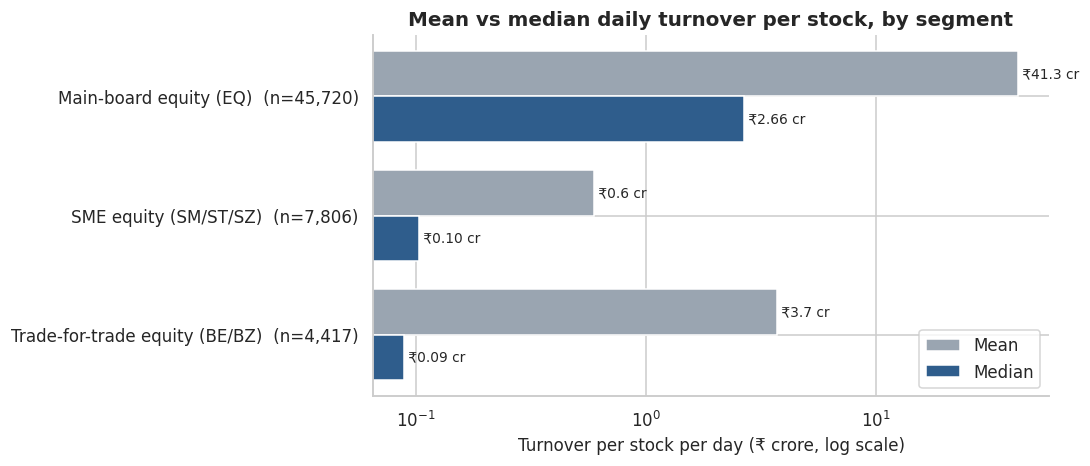

In [24]:
# Chart: mean vs median turnover per stock-day, by segment – the gap exposes the skew
seg = eq.groupby("segment")["turnover_cr"].agg(mean="mean", median="median", n="size").sort_values("median")
fig, ax = plt.subplots(figsize=(10, 4.4))
y, h = np.arange(len(seg)), 0.38
ax.barh(y + h/2, seg["mean"],   h, color=GREY, label="Mean")
ax.barh(y - h/2, seg["median"], h, color=BLUE, label="Median")
for yi, (mn, md) in enumerate(zip(seg["mean"], seg["median"])):
    ax.text(mn, yi + h/2, f" ₹{mn:,.1f} cr", va="center", fontsize=9); ax.text(md, yi - h/2, f" ₹{md:,.2f} cr", va="center", fontsize=9)
ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels([f"{s}  (n={n:,})" for s, n in zip(seg.index, seg["n"])])
ax.set_xlabel("Turnover per stock per day (₹ crore, log scale)"); ax.set_title("Mean vs median daily turnover per stock, by segment")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation — central tendency**

**What it shows:** the *typical* main-board stock-day trades **₹2.7 crore** (median), but the *average* is **₹41.3 crore** — 15.5× higher — because a few giants dominate. The same pattern shows in trades (mean 15,748 vs median 3,001) and price (₹842 vs ₹205). Delivery % is the exception: mean 56.1 % vs median 53.7 %, a nearly symmetric variable.

**Chart:** in every segment the mean sits far above the median — main board ₹41.3 cr vs ₹2.66 cr (15.5×), trade-for-trade ₹3.7 cr vs ₹0.09 cr (41×), SME ₹0.60 cr vs ₹0.10 cr (6×). A typical SME or trade-for-trade stock trades only about ₹9–10 lakh a day.

**Takeaway:** report **medians** for activity; the mean describes no real stock.

## 3.2 Variance & standard deviation
Standard deviation is in the variable's own units, so it cannot be compared across columns. The **coefficient of variation (CV = std ÷ mean)** puts every variable on one scale.

In [25]:
spread = pd.DataFrame({
    "variance": main[num_cols].var(),
    "std dev":  main[num_cols].std(),
    "CV (std ÷ mean)": main[num_cols].std() / main[num_cols].mean().abs(),
    "IQR (Q3 − Q1)": main[num_cols].quantile(.75) - main[num_cols].quantile(.25),
})
spread

,variance,std dev,CV (std ÷ mean),IQR (Q3 − Q1)
turnover_cr,"26,675.06",163.33,3.96,17.84
trades,"2,125,507,295.93","46,103.22",2.93,"14,626.00"
ret_pct,8.78,2.96,8.77,2.77
range_pct,8.66,2.94,0.67,2.97
deliv_pct,361.70,19.02,0.34,24.25
avg_trade_rs,"16,521,266,328.90","128,535.08",6.33,"10,323.16"
close,"13,814,282.79",3716.76,4.42,576.18


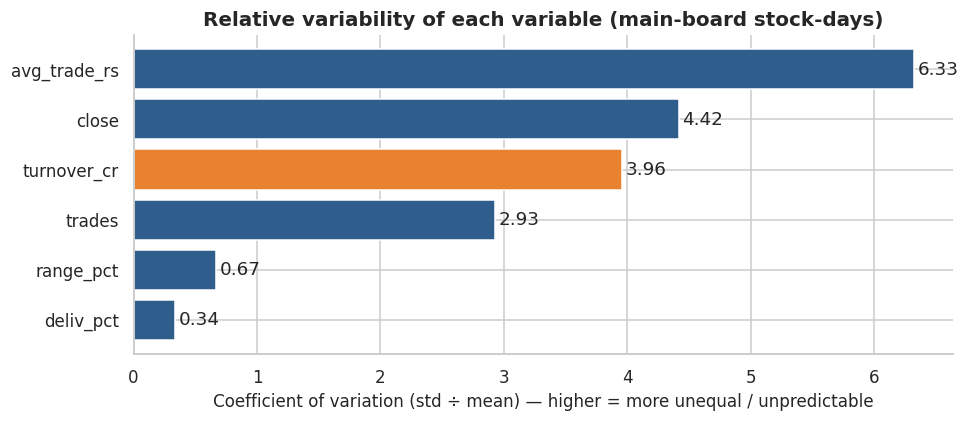

In [26]:
cv = spread["CV (std ÷ mean)"].drop("ret_pct").sort_values()          # mean return ≈ 0 makes its CV meaningless
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(cv.index, cv.values, color=[ORANGE if i == "turnover_cr" else BLUE for i in cv.index])
for b, v in zip(bars, cv.values): ax.text(v + 0.03, b.get_y() + b.get_height()/2, f"{v:.2f}", va="center")
ax.set_xlabel("Coefficient of variation (std ÷ mean) — higher = more unequal / unpredictable")
ax.set_title("Relative variability of each variable (main-board stock-days)")
plt.tight_layout(); plt.show()

**Interpretation — variance & standard deviation**

**What it shows:** turnover has a standard deviation of ₹163 crore against a mean of ₹41 crore (CV **3.96**); trade value per trade (6.3), price (4.4) and trade count (2.9) are just as unequal. Intraday range (0.67) and especially **delivery %** (0.34) are far more stable.

**Why it matters:** liquidity is wildly unequal across stocks, but investor behaviour — the delivery share — is comparatively uniform. Turnover averages are misleading, while delivery % can be compared across stocks directly.

**Note:** the IQR of turnover is only ₹17.8 crore (Q1 ₹0.19 cr → Q3 ₹18.0 cr): half of all stock-days sit in a narrow low-activity band while the tail runs into thousands of crore.

## 3.3 Skewness, kurtosis & outlier detection (IQR / box plot)

In [27]:
shape_stats = pd.DataFrame({
    "skewness":           main[num_cols].skew(),
    "excess kurtosis":    main[num_cols].kurt(),
    "skewness after log": np.log1p(main[num_cols].clip(lower=0)).skew(),
})
shape_stats

,skewness,excess kurtosis,skewness after log
turnover_cr,10.69,164.54,0.90
trades,14.59,392.17,-0.35
ret_pct,-0.85,71.60,1.61
range_pct,2.24,8.81,-0.02
deliv_pct,0.26,-0.15,-1.42
avg_trade_rs,27.35,1009.94,0.12
close,21.20,597.25,-0.09


In [28]:
def iqr_summary(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "lower fence": lo, "upper fence": hi, "outliers": int(((s < lo) | (s > hi)).sum())})

out_tbl = main[["turnover_cr", "trades", "ret_pct", "range_pct", "deliv_pct"]].apply(iqr_summary).T
out_tbl["% of stock-days"] = out_tbl["outliers"] / len(main) * 100
out_tbl

,Q1,Q3,lower fence,upper fence,outliers,% of stock-days
turnover_cr,0.19,18.03,-26.57,44.79,6969.00,15.24
trades,378.00,"15,004.00","-21,561.00","36,943.00",5031.00,11.00
ret_pct,-1.82,0.95,-5.98,5.10,2135.00,4.67
range_pct,2.52,5.49,-1.93,9.94,2077.00,4.54
deliv_pct,43.64,67.89,7.27,104.27,146.00,0.32


In [29]:
# The most extreme one-day moves in the whole equity universe – real events or data artefacts?
eq.loc[eq["ret_pct"].abs() > 50, ["symbol", "series", "date", "prev_close", "close", "ret_pct", "turnover_cr"]].assign(date=lambda d: d["date"].dt.strftime("%d-%b")).sort_values("ret_pct").reset_index(drop=True)

,symbol,series,date,prev_close,close,ret_pct,turnover_cr
0,BHAGYANGR,BE,08-Oct,454.55,41.40,-90.89,0.48
1,JSWDULUX,EQ,22-Oct,2994.80,302.20,-89.91,5.75
2,VERANDA,BE,06-Oct,212.76,29.72,-86.03,1.22
3,AZADIND,EQ,23-Oct,81.58,15.34,-81.20,0.13
4,BUILDPRO,EQ,08-Oct,1302.00,250.20,-80.78,9.88
5,BANSALWIRE,EQ,16-Oct,315.60,61.65,-80.47,2.76
6,ARIHANTACA,SM,07-Oct,515.00,230.00,-55.34,0.06
7,AISL,SM,09-Oct,70.35,33.45,-52.45,0.15
8,MONEYVIEW,EQ,01-Oct,34.00,53.88,58.47,3698.79
9,TONBO,EQ,23-Oct,700.00,1133.80,61.97,2245.65


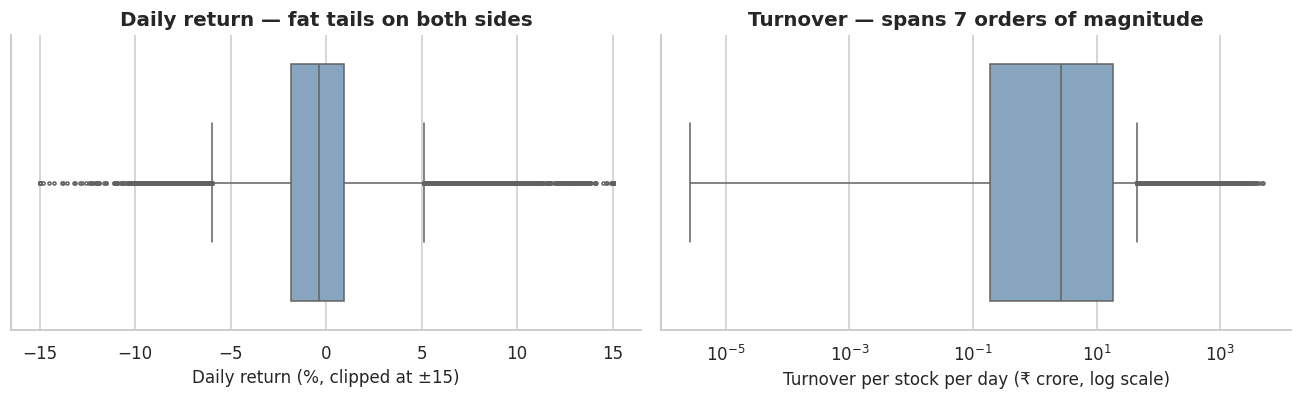

In [30]:
# Box plots: daily returns (clipped to ±15 % for readability) and turnover (log scale)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(x=main["ret_pct"].clip(-15, 15), color="#7FA6C9", fliersize=2, ax=axes[0])
axes[0].set_title("Daily return — fat tails on both sides"); axes[0].set_xlabel("Daily return (%, clipped at ±15)")
sns.boxplot(x=main["turnover_cr"], color="#7FA6C9", fliersize=2, ax=axes[1]); axes[1].set_xscale("log")
axes[1].set_title("Turnover — spans 7 orders of magnitude"); axes[1].set_xlabel("Turnover per stock per day (₹ crore, log scale)")
plt.tight_layout(); plt.show()

In [31]:
# Decision on outliers: what does winsorising returns at ±25 % change?
wins = main["ret_pct"].clip(-25, 25)
pd.DataFrame({"raw returns": main["ret_pct"].agg(["count", "mean", "median", "std"]),
              "winsorised ±25 %": wins.agg(["count", "mean", "median", "std"])})

,raw returns,winsorised ±25 %
count,"45,720.00","45,720.00"
mean,-0.34,-0.33
median,-0.36,-0.36
std,2.96,2.83


**Interpretation — skewness, kurtosis & outliers**

**Shape:** turnover is extremely right-skewed (skewness **10.7**, excess kurtosis 165); trades (14.6), average trade size (27.4) and price (21.2) likewise. A log transform pulls turnover's skew down to 0.9 and trade size's to 0.12 — hence the log scales in the charts. Daily returns are **fat-tailed** (skew −0.85, kurtosis 72): most days are small moves, a few are huge. Delivery % is almost normal (skew 0.26, kurtosis −0.15).

**Outliers (IQR rule):** 15.2 % of stock-days have outlier turnover (above ₹44.8 crore), 4.7 % outlier returns (beyond −6.0 % / +5.1 %) and 4.5 % outlier intraday range (above 9.9 %). In a market, big turnover is not an error — it is the information.

**Extreme moves:** the ten moves beyond ±50 % are the six 80–91 % falls (likely splits or bonus issues), two SME falls of 52–55 %, and the two large listing-day jumps (+58 % and +62 %) — real events, not data errors.

**Decision — keep, flag, winsorise.** Removing outliers would delete the market's most active days. Winsorising returns at ±25 % leaves the mean (−0.34 % → −0.33 %) and median (−0.36 %) almost unchanged and trims the standard deviation from 2.96 % to 2.83 %, so I use medians, log scales and rank-based tests.

## 3.4 Do the patterns hold up statistically? (hypothesis tests)
Trading data are heavily skewed, so I use **non-parametric** tests (Spearman, Mann–Whitney U, Kruskal–Wallis) that do not assume a normal distribution. Significance level α = 0.05. Each result is paired with an *effect size* so statistical significance is not mistaken for business importance.

In [32]:
def cles(a, b):
    """Common-language effect size: probability that a random value from `a` is larger than one from `b`."""
    return stats.mannwhitneyu(a, b).statistic / (len(a) * len(b))

# --- T1: is higher conviction (delivery %) linked to a bigger SAME-DAY price move?
rho1, p1 = stats.spearmanr(liquid["deliv_pct"], liquid["ret_pct"])
print(f"T1  Delivery % vs same-day return          Spearman ρ = {rho1:+.3f}  (p = {p1:.1e}, n = {len(liquid):,})")

# --- T2: do up-days have higher delivery % than down-days?
up, dn = liquid.loc[liquid["ret_pct"] > 0, "deliv_pct"], liquid.loc[liquid["ret_pct"] < 0, "deliv_pct"]
print(f"T2  Delivery %, up-days vs down-days       median {up.median():.1f} % vs {dn.median():.1f} %  (p = {stats.mannwhitneyu(up, dn).pvalue:.1e}, P(up > down) = {cles(up, dn):.1%})")

# --- T3: do industries differ in delivery % and in performance? (Nifty 500, industries with ≥ 5 stocks)
nf = full[full["in_nifty500"]]
big = nf["industry"].value_counts()[lambda s: s >= 5].index
nfb = nf[nf["industry"].isin(big)]
h3, p3 = stats.kruskal(*[g["avg_deliv_pct"] for _, g in nfb.groupby("industry")])
h4, p4 = stats.kruskal(*[g["cum_ret_pct"] for _, g in nfb.groupby("industry")])
print(f"T3  Delivery % differs across industries   Kruskal–Wallis H = {h3:.1f}  (p = {p3:.1e}, {len(big)} industries)")
print(f"T4  Period return differs across industries Kruskal–Wallis H = {h4:.1f}  (p = {p4:.1e})")

# --- T5: Nifty 500 vs the rest of the main board (stocks listed ≥ 15 sessions)
fm = full[full["segment"].str.startswith("Main")]
a, b_ = fm[fm["in_nifty500"]], fm[~fm["in_nifty500"]]
for col, lab in [("avg_deliv_pct", "Delivery %"), ("avg_range_pct", "Intraday range %"), ("avg_turnover_cr", "Avg daily turnover")]:
    print(f"T5  {lab:18s} Nifty 500 median {a[col].median():7.2f} vs rest {b_[col].median():7.2f}   (p = {stats.mannwhitneyu(a[col], b_[col]).pvalue:.1e}, n = {len(a)} vs {len(b_)})")

# --- T6: does conviction PREDICT the next session's return?
nx = liquid.dropna(subset=["ret_next"]); nx = nx[nx["ret_next"].abs() <= 25]
rho6, p6 = stats.spearmanr(nx["deliv_pct"], nx["ret_next"])
hi, lo = nx.loc[nx["deliv_pct"] >= 60, "ret_next"], nx.loc[nx["deliv_pct"] < 35, "ret_next"]
print(f"T6  Delivery % vs NEXT-day return          Spearman ρ = {rho6:+.3f}  (p = {p6:.1e}, n = {len(nx):,})")
print(f"T7  Next-day return, high (≥60 %) vs low (<35 %) delivery   mean {hi.mean():+.3f} % vs {lo.mean():+.3f} %  (median {hi.median():+.2f} vs {lo.median():+.2f};  p = {stats.mannwhitneyu(hi, lo).pvalue:.1e})")

# --- T8: are trade-for-trade (BE/BZ) shares more volatile than main-board shares?
t2t, mb = eq.loc[eq["series"].isin(["BE", "BZ"]), "range_pct"], eq.loc[eq["series"] == "EQ", "range_pct"]
print(f"T8  Intraday range, trade-for-trade vs main median {t2t.median():.2f} % vs {mb.median():.2f} %  (p = {stats.mannwhitneyu(t2t, mb).pvalue:.1e}, P(T2T wider) = {cles(t2t, mb):.0%})")

T1  Delivery % vs same-day return          Spearman ρ = -0.115  (p = 6.5e-82, n = 27,815)
T2  Delivery %, up-days vs down-days       median 45.6 % vs 48.7 %  (p = 1.9e-77, P(up > down) = 43.5%)
T3  Delivery % differs across industries   Kruskal–Wallis H = 60.0  (p = 1.0e-06, 18 industries)
T4  Period return differs across industries Kruskal–Wallis H = 80.1  (p = 3.7e-10)
T5  Delivery %         Nifty 500 median   46.81 vs rest   55.07   (p = 7.7e-36, n = 493 vs 2183)
T5  Intraday range %   Nifty 500 median    3.23 vs rest    4.52   (p = 1.3e-63, n = 493 vs 2183)
T5  Avg daily turnover Nifty 500 median   89.18 vs rest    1.66   (p = 2.5e-206, n = 493 vs 2183)
T6  Delivery % vs NEXT-day return          Spearman ρ = +0.042  (p = 1.2e-11, n = 26,199)
T7  Next-day return, high (≥60 %) vs low (<35 %) delivery   mean -0.171 % vs -0.440 %  (median -0.11 vs -0.54;  p = 1.0e-11)
T8  Intraday range, trade-for-trade vs main median 4.64 % vs 3.75 %  (p = 1.4e-31, P(T2T wider) = 55%)


**Interpretation — hypothesis tests**

- **T1 / T2 — Delivery rises when prices fall.** Delivery % and same-day return are *negatively* related (ρ = −0.12, p < 0.001, n = 27,815). Up-days have a median delivery of 45.6 % vs 48.7 % on down-days; a random up-day has the higher delivery in only 43.5 % of pairings. Rallies were more intraday-driven; sell-offs were backed by real delivery. *(Delivery counts both sides of a trade, so this suggests investors exiting rather than buying.)*
- **T3 / T4 — Industries differ.** Delivery % (H = 60.0, p < 0.001) and period returns (H = 80.1, p < 0.001) both differ significantly across the 18 industries with at least 5 stocks.
- **T5 — Nifty 500 vs the rest.** Nifty 500 stocks have *lower* delivery (median 46.8 % vs 55.1 %), a *narrower* daily range (3.2 % vs 4.5 %) and 54× more turnover (₹89 cr vs ₹1.7 cr a day) — all p < 0.001.
- **T6 / T7 — Does conviction predict tomorrow?** Faintly yes statistically, no practically: ρ = +0.04, and the next-day median return after high-delivery days (≥ 60 %) was −0.11 % vs −0.54 % after speculative days (< 35 %) — a 0.4-point gap in a falling market. With 26,199 observations tiny effects become "significant"; this is not a tradable edge.
- **T8 — Trade-for-trade stocks are wilder.** Their intraday range is wider (median 4.6 % vs 3.8 %, p < 0.001); a random trade-for-trade stock-day is wider than a main-board one in 55 % of pairings.

**Reading the p-values:** p < 0.05 means a pattern is unlikely to be chance. With tens of thousands of rows almost everything is "significant", so every p-value is shown beside an effect size (medians, ρ, or the share of pairings).

## 3.5 Visual analysis
*Every chart sits in its own cell and is followed by an interpretation: what the chart says, which columns it uses, and the business takeaway.*

---
### A. Univariate analysis — one variable at a time

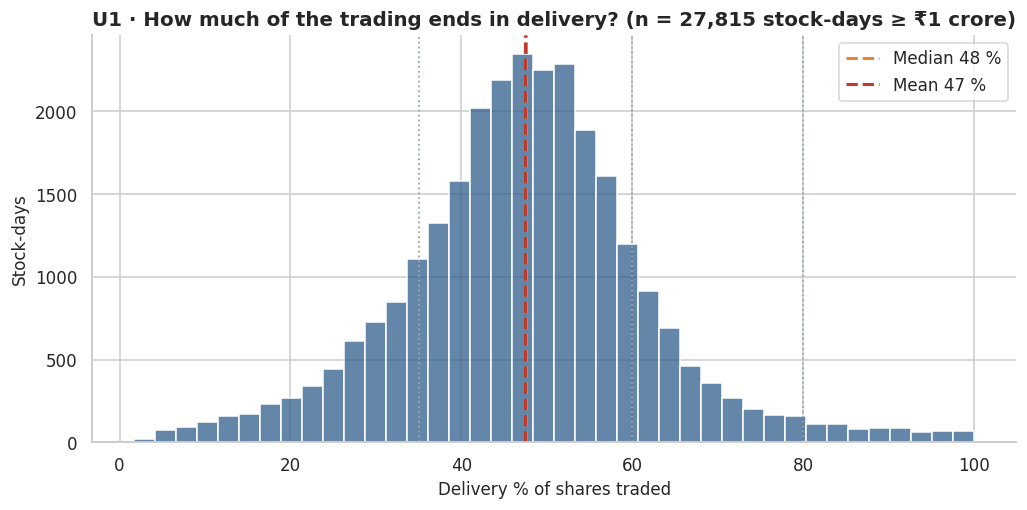

In [33]:
# U1 — How much of the trading is genuine delivery?
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.histplot(liquid["deliv_pct"], bins=40, color=BLUE, ax=ax)
med, mean = liquid["deliv_pct"].median(), liquid["deliv_pct"].mean()
ax.axvline(med,  color=ORANGE, ls="--", lw=2, label=f"Median {med:.0f} %")
ax.axvline(mean, color=RED,    ls="--", lw=2, label=f"Mean {mean:.0f} %")
for x in (35, 60, 80): ax.axvline(x, color=GREY, ls=":", lw=1.2)
ax.set_xlabel("Delivery % of shares traded"); ax.set_ylabel("Stock-days")
ax.set_title(f"U1 · How much of the trading ends in delivery? (n = {len(liquid):,} stock-days ≥ ₹1 crore)")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation — U1 (histogram of `deliv_pct`)**

**What it shows:** the share of each stock's daily volume that ended in delivery, for the 27,815 stock-days with at least ₹1 crore traded. A bell shape centred on **48 %** (median 47.6 %, mean 47.5 %).

**Bands:** 17 % of stock-days were *speculative* (< 35 % delivery), 68 % *mixed* (35–60 %), 13 % *conviction* (60–80 %) and only 2.5 % *high conviction* (80 %+).

**Takeaway:** on a typical liquid stock-day roughly half the traded shares are squared off the same day — intraday trading is as big as investing. By value the market-wide figure is lower still: about 43 % on average (39.5 %–45.8 % across sessions).

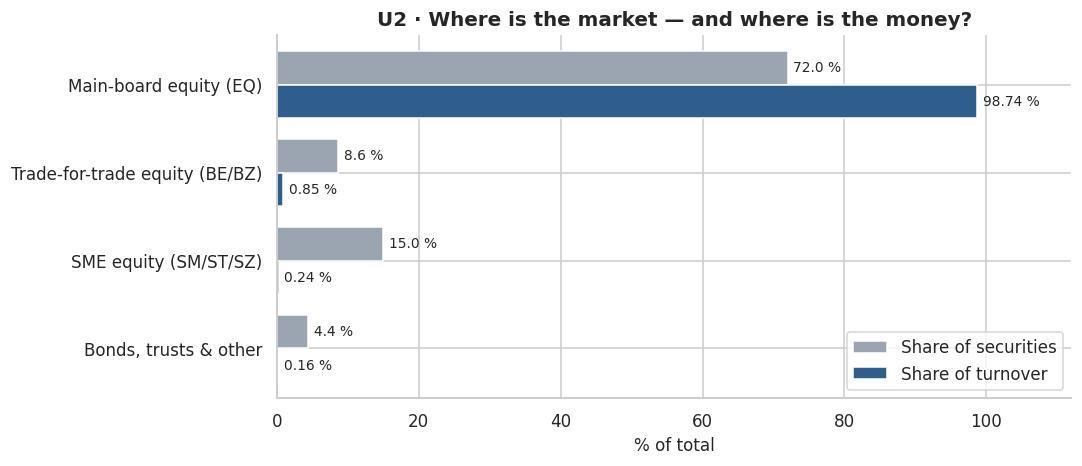

In [34]:
# U2 — Share of securities vs share of turnover, by segment
sh = df.groupby("segment").agg(securities=("symbol", "nunique"), turnover=("turnover_cr", "sum"))
sh = (sh / sh.sum() * 100).sort_values("turnover")
fig, ax = plt.subplots(figsize=(10, 4.4))
y, h = np.arange(len(sh)), 0.38
ax.barh(y + h/2, sh["securities"], h, color=GREY, label="Share of securities")
ax.barh(y - h/2, sh["turnover"],   h, color=BLUE, label="Share of turnover")
for yi, (s_, t_) in enumerate(zip(sh["securities"], sh["turnover"])):
    ax.text(s_ + 0.8, yi + h/2, f"{s_:.1f} %", va="center", fontsize=9); ax.text(t_ + 0.8, yi - h/2, f"{t_:.2f} %", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(sh.index); ax.set_xlim(0, 112); ax.set_xlabel("% of total")
ax.set_title("U2 · Where is the market — and where is the money?"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation — U2 (grouped bars of `segment`)**

**What it shows:** each segment's share of securities (grey) versus its share of turnover (blue). Main-board equity is **72 % of securities (2,754) but 98.7 % of turnover**. SME equity is 15 % of securities (572) yet only 0.24 % of turnover; trade-for-trade shares are 8.6 % (329) and 0.85 %; bonds, REITs / InvITs and other instruments are 4.4 % (170) and 0.16 %.

**Takeaway:** the long tail of the market — about 28 % of securities — is almost untraded. Liquidity risk, not price risk, is the main hazard there, and it is why the rest of the analysis focuses on the main board.

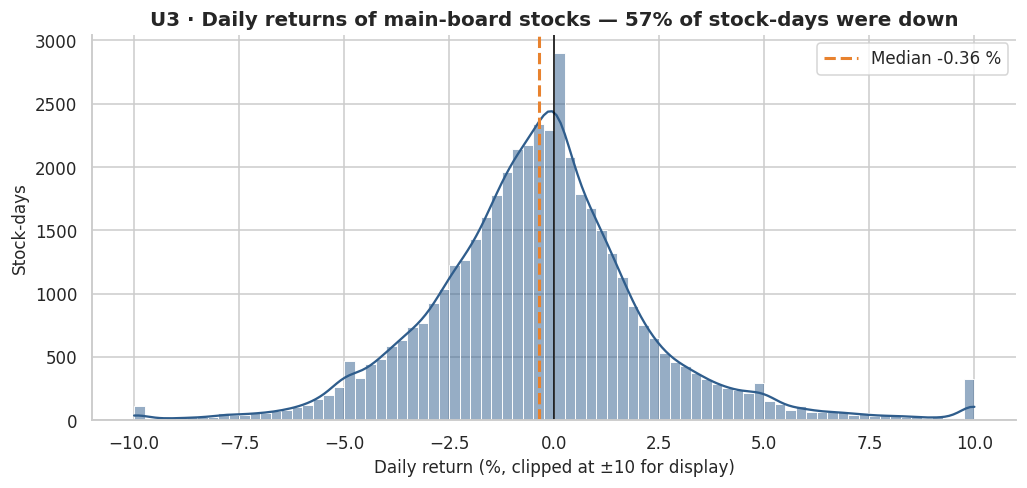

In [35]:
# U3 — Distribution of daily returns
fig, ax = plt.subplots(figsize=(9.5, 4.6))
r = main["ret_pct"].clip(-10, 10)
sns.histplot(r, bins=80, kde=True, color=BLUE, ax=ax)
ax.axvline(0, color="black", lw=1)
ax.axvline(main["ret_pct"].median(), color=ORANGE, ls="--", lw=2, label=f"Median {main['ret_pct'].median():+.2f} %")
ax.set_xlabel("Daily return (%, clipped at ±10 for display)"); ax.set_ylabel("Stock-days")
ax.set_title(f"U3 · Daily returns of main-board stocks — {(main['ret_pct'] < 0).mean():.0%} of stock-days were down")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation — U3 (histogram of `ret_pct`)**

**What it shows:** the distribution of daily returns (clipped at ±10 % for display). It is centred slightly below zero — median **−0.36 %**, mean −0.34 % — with **57 % of stock-days down versus 42 % up**; 64 % of stock-days moved less than ±2 %, and only 6.5 % moved more than ±5 %.

**Takeaway:** October was a weak, broad-based month: on a typical day more stocks fell than rose. Context matters for everything that follows — the conclusions about delivery and sectors describe a *falling* market.

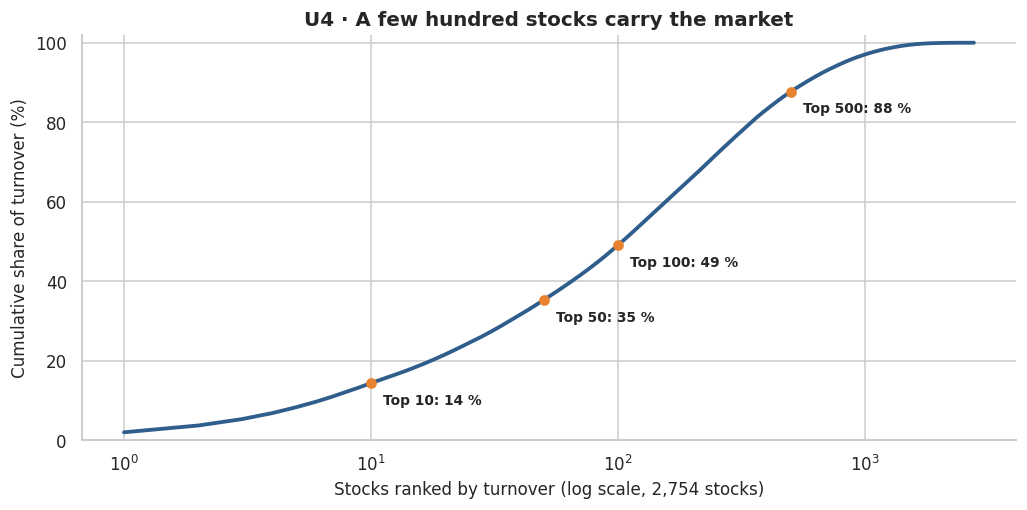

In [36]:
# U4 — How concentrated is trading? (Pareto / Lorenz-style curve)
tot = main.groupby("symbol")["turnover_cr"].sum().sort_values(ascending=False)
cum = tot.cumsum() / tot.sum() * 100
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(np.arange(1, len(cum) + 1), cum.values, color=BLUE, lw=2.5)
for k in (10, 50, 100, 500):
    ax.scatter(k, cum.iloc[k - 1], color=ORANGE, zorder=5); ax.annotate(f"Top {k}: {cum.iloc[k-1]:.0f} %", (k, cum.iloc[k - 1]), textcoords="offset points", xytext=(8, -14), fontsize=9, fontweight="bold")
ax.set_xscale("log"); ax.set_xlabel(f"Stocks ranked by turnover (log scale, {len(cum):,} stocks)"); ax.set_ylabel("Cumulative share of turnover (%)")
ax.set_ylim(0, 102); ax.set_title("U4 · A few hundred stocks carry the market"); plt.tight_layout(); plt.show()

**Interpretation — U4 (cumulative turnover curve of `turnover_cr` by `symbol`)**

**What it shows:** cumulative share of turnover when stocks are ranked from most to least traded. The **top 10 carry 14.4 %** of main-board turnover, the **top 50 35.3 %**, the **top 100 49.1 %** and the **top 500 87.7 %**. Just 104 of 2,754 stocks (4 %) account for half of all turnover; 346 account for 80 %.

**Takeaway:** trading is heavily concentrated, but not only in blue chips. The top 10 includes PC Jeweller (₹16.6 a share, 20 % delivery) and Moneyview (+58 % on ₹3,699 crore on 1 Oct) next to HDFC Bank (57 % delivery). High turnover is not the same as high conviction.

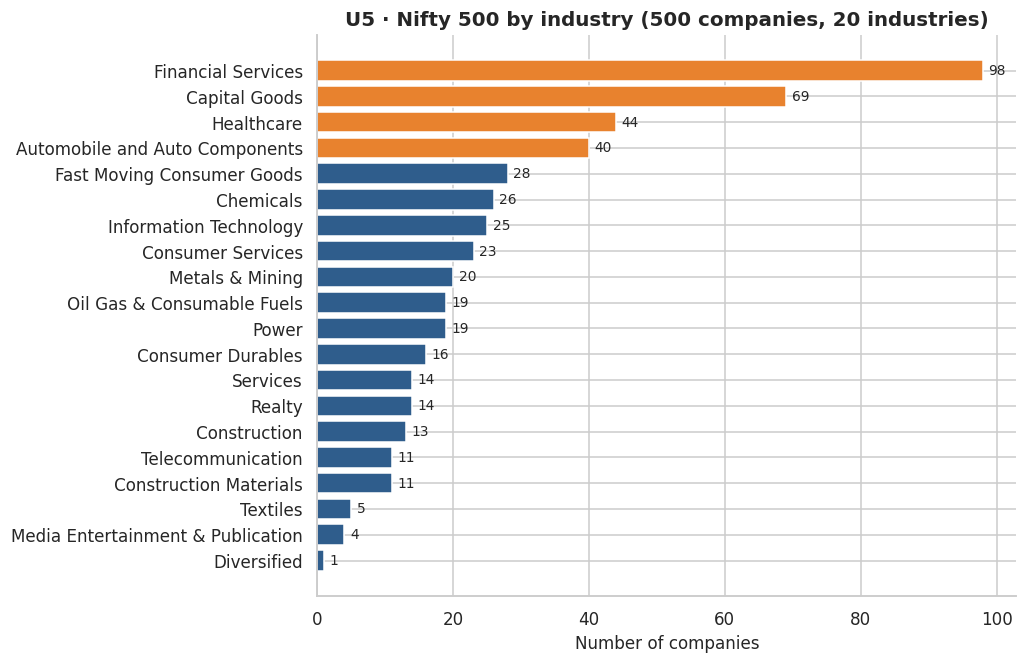

In [37]:
# U5 — What does the Nifty 500 consist of?
comp = nifty[nifty["symbol"].isin(df["symbol"])]["industry"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9.5, 6.2))
bars = ax.barh(comp.index, comp.values, color=[ORANGE if v >= 40 else BLUE for v in comp.values])
for b, v in zip(bars, comp.values): ax.text(v + 0.8, b.get_y() + b.get_height()/2, f"{v}", va="center", fontsize=9)
ax.set_xlabel("Number of companies"); ax.set_title(f"U5 · Nifty 500 by industry ({comp.sum()} companies, {len(comp)} industries)")
plt.tight_layout(); plt.show()

**Interpretation — U5 (bar chart of `industry`)**

**What it shows:** the 500 Nifty 500 companies, by industry. Financial Services (98), Capital Goods (69), Healthcare (44), Automobiles & Auto Components (40), FMCG (28) and Chemicals (26) lead; 42 % of the index sits in the first three.

**Takeaway:** the Nifty 500 is a financials-and-industrials index, so sector conclusions are most reliable for the larger industries. Media (4 companies) and Diversified (1) have fewer than 5 stocks and are left out of industry comparisons.

---
### B. Bivariate analysis — relationships between two variables

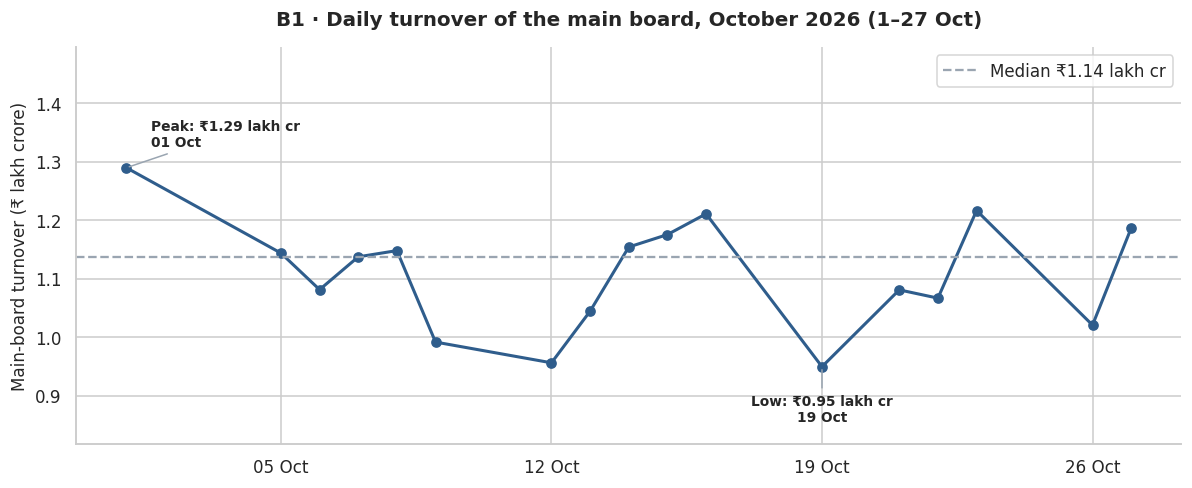

In [38]:
# B1 — The market's daily turnover
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(11, 4.6))
t = daily["turnover_cr"] / 1e5                                   # ₹ lakh crore
ax.plot(daily.index, t, marker="o", color=BLUE, lw=2)
ax.axhline(t.median(), color=GREY, ls="--", lw=1.5, label=f"Median ₹{t.median():.2f} lakh cr")
for d_, v_, lab in [(t.idxmax(), t.max(), "Peak"), (t.idxmin(), t.min(), "Low")]:
    ax.annotate(f"{lab}: ₹{v_:.2f} lakh cr\n{d_:%d %b}", (d_, v_), textcoords="offset points", xytext=((16, 14) if (d_ - t.index.min()) / (t.index.max() - t.index.min()) < 0.3 else (-62, -6)) if lab == "Peak" else (0, -36), ha="left" if (lab == "Peak" and (d_ - t.index.min()) / (t.index.max() - t.index.min()) < 0.3) else "center", fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_ylim(t.min() * 0.86, t.max() * 1.16)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ax.set_ylabel("Main-board turnover (₹ lakh crore)"); ax.set_title("B1 · Daily turnover of the main board, October 2026 (1–27 Oct)", pad=14)
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

**Interpretation — B1 (line chart: `date` vs daily `turnover_cr`)**

**What it shows:** total main-board turnover per session. A normal day trades about **₹1.1 lakh crore** (median 1.14, range 0.95–1.29). The busiest session was **1 Oct (₹1.29 lakh crore)**, followed by 23 Oct (1.22) and 16 Oct (1.21); the quietest was 19 Oct (0.95), the session before the 20 Oct holiday. Mondays are the quietest weekday (₹1.02 lakh crore against 1.10–1.17 for the others).

**Takeaway:** turnover is steady — the first and last weeks both averaged about ₹1.1 lakh crore — even as prices fell. It rises somewhat with the size of the day's price move (correlation 0.25 with the absolute move of the median stock), so big down-days and big up-days draw more trading. The largest single stock-day was Bharti Airtel on 16 Oct (₹4,826 crore, 4 % of that session).

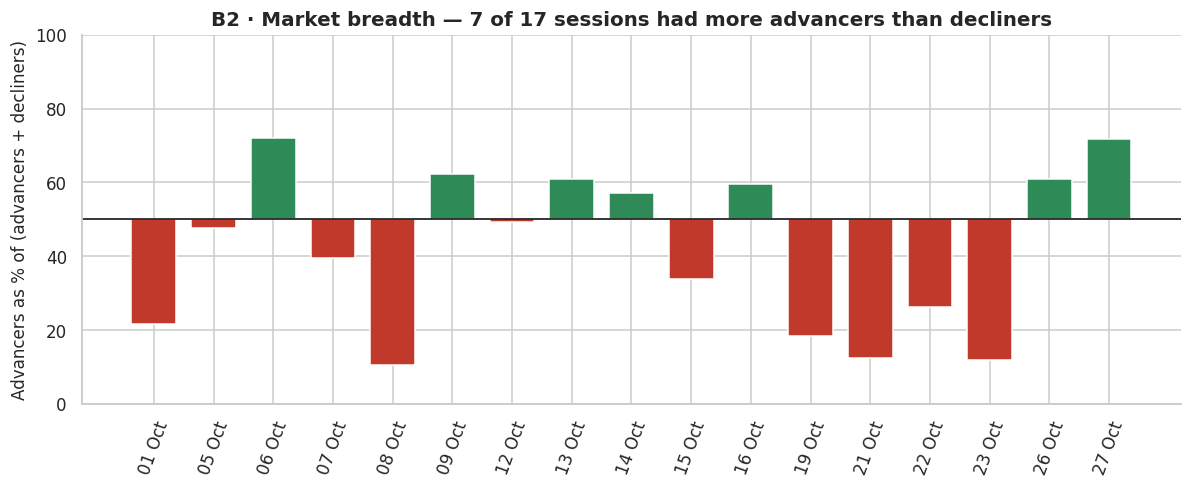

In [39]:
# B2 — Market breadth: what share of stocks went up each day?
fig, ax = plt.subplots(figsize=(11, 4.6))
cols = [GREEN if v >= 50 else RED for v in daily["breadth_pct"]]
ax.bar(daily.index.strftime("%d %b"), daily["breadth_pct"] - 50, bottom=50, color=cols, width=0.75)
ax.axhline(50, color="black", lw=1)
ax.set_ylabel("Advancers as % of (advancers + decliners)"); ax.set_ylim(0, 100)
ax.set_title(f"B2 · Market breadth — {int((daily['breadth_pct'] >= 50).sum())} of {len(daily)} sessions had more advancers than decliners")
plt.xticks(rotation=70); plt.tight_layout(); plt.show()

**Interpretation — B2 (bar chart: `date` vs advancers share)**

**What it shows:** the share of stocks that rose (advancers ÷ [advancers + decliners]) in each session. Only **7 of 17 sessions** had more advancers than decliners; average breadth was 42.2 %. The worst days were 8 Oct (10.6 % rose, median stock −2.3 %), 23 Oct (11.8 %, −2.4 %) and 21 Oct (12.6 %, −2.2 %); the best was 6 Oct (72.1 %, median stock +0.9 %).

**Takeaway:** breadth tracks the typical stock's move almost perfectly (correlation 0.98). It swung from 72 % to 11 % in just two sessions (6 → 8 Oct) and was weakest at the end of the month: sell-offs were sharp and one-directional — days when nine in ten stocks fell — while rallies were milder.

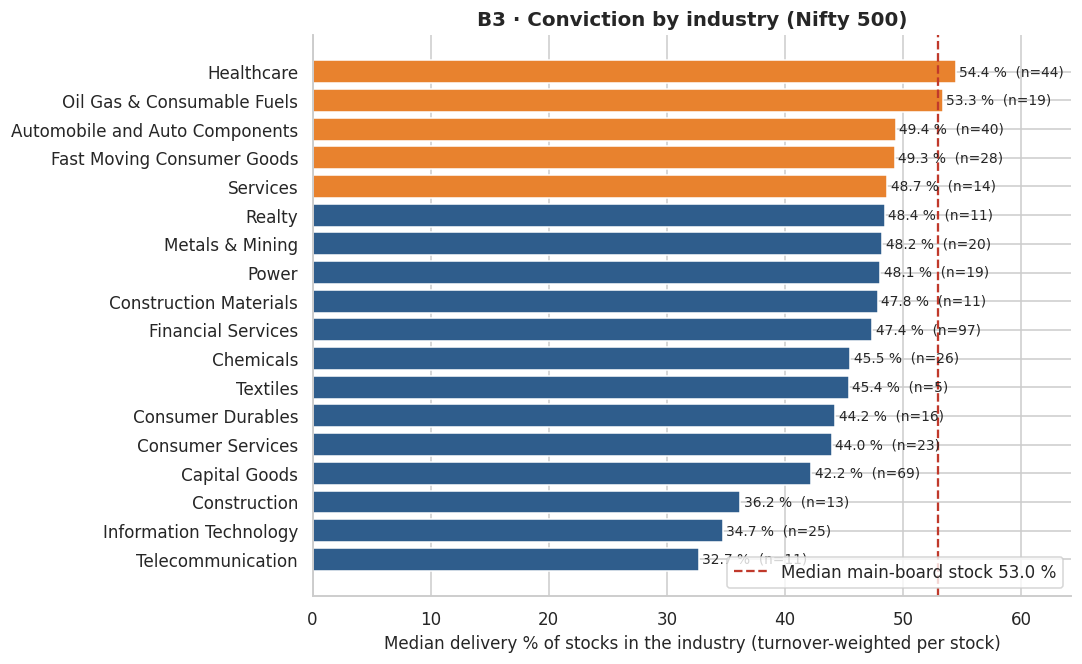

In [40]:
# B3 — Which industries attract the most conviction (delivery)?  Nifty 500 stocks, industries with ≥ 5 stocks
ind = (nfb.groupby("industry").agg(n=("company", "size"), deliv=("avg_deliv_pct", "median"), ret=("cum_ret_pct", "median"), turnover=("total_turnover_cr", "sum"))
         .sort_values("deliv"))
mkt_deliv = fm["avg_deliv_pct"].median()
fig, ax = plt.subplots(figsize=(10, 6.2))
bars = ax.barh(ind.index, ind["deliv"], color=[ORANGE if v >= ind["deliv"].quantile(.75) else BLUE for v in ind["deliv"]])
for b, (v, n_) in zip(bars, zip(ind["deliv"], ind["n"])): ax.text(v + 0.3, b.get_y() + b.get_height()/2, f"{v:.1f} %  (n={n_})", va="center", fontsize=9)
ax.axvline(mkt_deliv, color=RED, ls="--", lw=1.5, label=f"Median main-board stock {mkt_deliv:.1f} %")
ax.set_xlim(0, ind["deliv"].max() * 1.18); ax.set_xlabel("Median delivery % of stocks in the industry (turnover-weighted per stock)")
ax.set_title("B3 · Conviction by industry (Nifty 500)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation — B3 (bar chart: `industry` vs median `avg_deliv_pct`)**

**What it shows:** median delivery % of Nifty 500 stocks by industry (18 industries with at least 5 stocks). Highest conviction: Healthcare (54.4 %), Oil & Gas (53.3 %), Automobiles (49.4 %) and FMCG (49.3 %). Lowest: Telecommunication (32.7 %), Information Technology (34.7 %), Construction (36.2 %) and Capital Goods (42.2 %). Only Healthcare and Oil & Gas are above the median main-board stock (53.0 %).

**Takeaway:** conviction is highest in defensive, cash-generating industries and lowest in trading-heavy ones, where a few large names dominate volume. The differences are statistically real (T3) — about 22 points between the extremes.

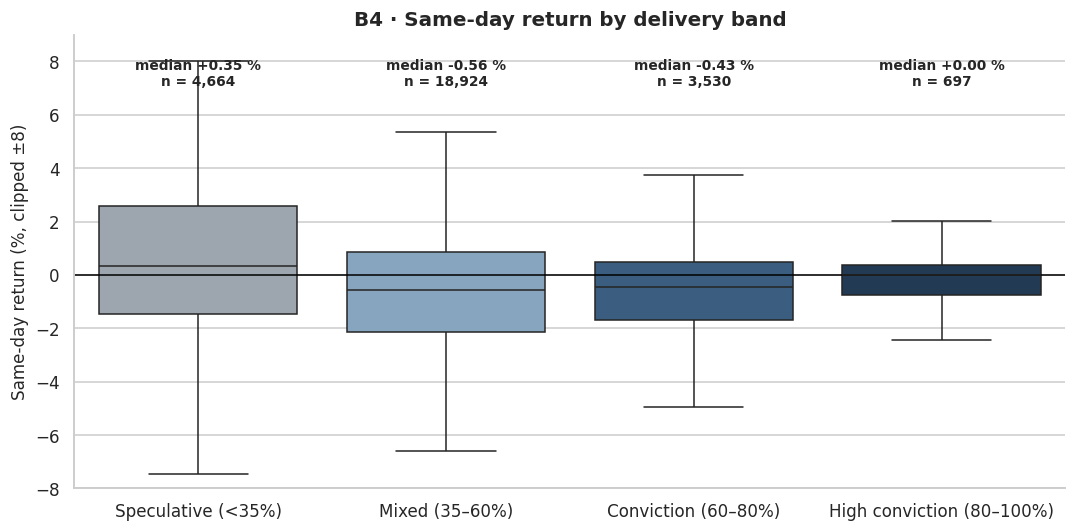

In [41]:
# B4 — Does higher conviction come with different returns?
order = list(liquid["deliv_band"].cat.categories)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=liquid.assign(r=liquid["ret_pct"].clip(-8, 8)), x="deliv_band", y="r", order=order, hue="deliv_band", dodge=False, legend=False,
            palette=[GREY, "#7FA6C9", BLUE, NAVY], showfliers=False, ax=ax)
ax.axhline(0, color="black", lw=1)
meds = liquid.groupby("deliv_band", observed=True)["ret_pct"].median(); cnt = liquid["deliv_band"].value_counts()
for i, c in enumerate(order): ax.text(i, 7.1, f"median {meds[c]:+.2f} %\nn = {cnt[c]:,}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(-8, 9); ax.set_xlabel(""); ax.set_ylabel("Same-day return (%, clipped ±8)"); ax.set_title("B4 · Same-day return by delivery band")
plt.tight_layout(); plt.show()

**Interpretation — B4 (box plot: `deliv_band` vs `ret_pct`)**

**What it shows:** same-day return for each delivery band (liquid stock-days; extremes hidden). The *speculative* band (< 35 % delivery) is the only one with a clearly positive median return (**+0.35 %**, mean +0.82 %); *mixed* days have a median of **−0.56 %**, *conviction* days −0.43 %, and the small *high-conviction* band (697 stock-days) sits at 0.00 %.

**Takeaway:** the strongest up-moves came on low-delivery (intraday-driven) days and the weakest on days with more delivery — consistent with T1: in this market, *delivery went with selling*. Delivery % tells you **who is trading**; on its own it is not a bullish signal.

---
### C. Multivariate analysis — three or more variables together

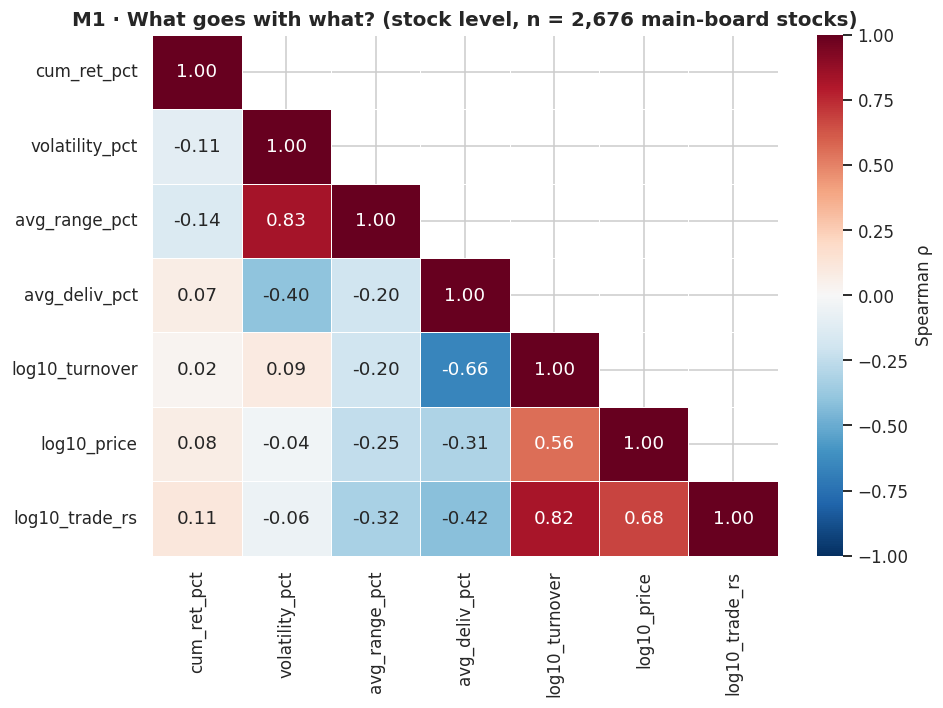

In [42]:
# M1 — Correlation heatmap of stock-level measures (Spearman: robust to skew and outliers)
sl = fm.assign(log10_turnover=np.log10(fm["avg_turnover_cr"]), log10_price=np.log10(fm["last_close"]), log10_trade_rs=np.log10(fm["avg_trade_rs"]))
corr_cols = ["cum_ret_pct", "volatility_pct", "avg_range_pct", "avg_deliv_pct", "log10_turnover", "log10_price", "log10_trade_rs"]
corr = sl[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.8, 6.6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title(f"M1 · What goes with what? (stock level, n = {len(sl):,} main-board stocks)"); plt.tight_layout(); plt.show()

**Interpretation — M1 (heatmap of 7 stock-level measures)**

**What it shows:** Spearman correlations between stock-level measures (2,676 main-board stocks). The strongest links are structural: volatility with intraday range (**+0.83**), trade size with turnover (+0.82) and turnover with price level (+0.56).

**Conviction:** delivery % falls as liquidity rises (**−0.66** with turnover) and as volatility rises (−0.40): the more a stock is traded, the more of that trading is intraday.

**Performance:** period return has almost no relationship with anything (|ρ| ≤ 0.14), including delivery (+0.07) and turnover (+0.02).

**Takeaway:** liquidity and conviction move in opposite directions, but neither explains who performed best this month.

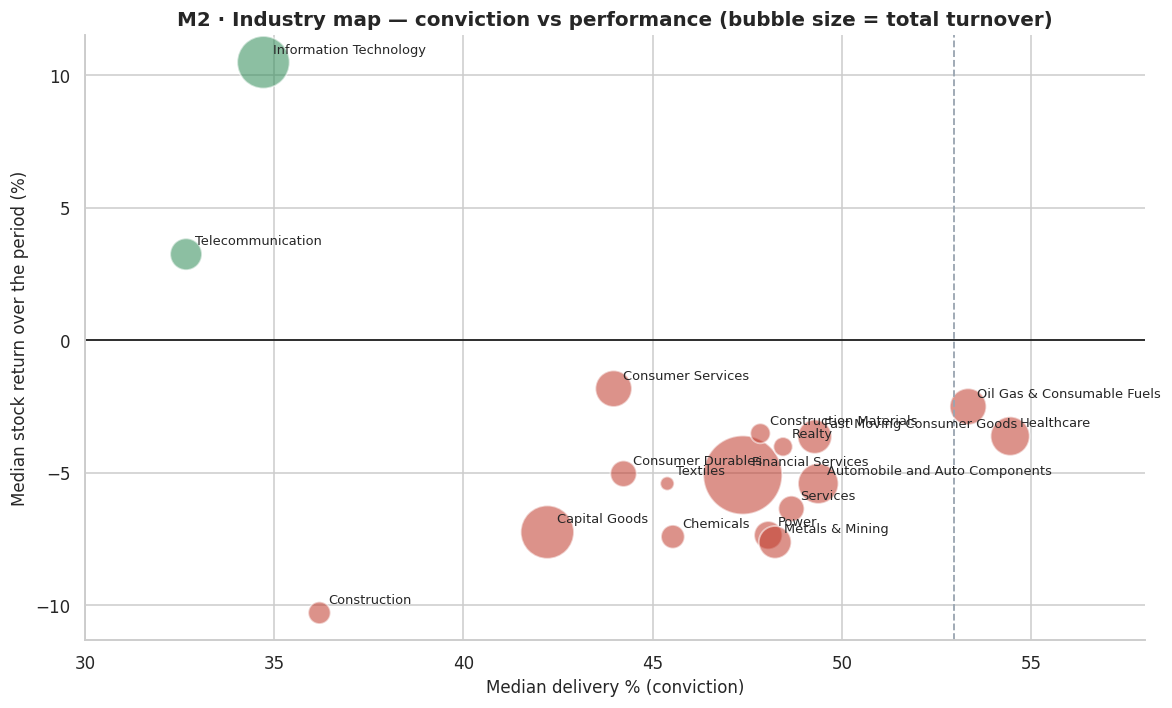

In [43]:
# M2 — Industry map: conviction vs performance, bubble = traded value
fig, ax = plt.subplots(figsize=(11, 6.6))
sc = ax.scatter(ind["deliv"], ind["ret"], s=ind["turnover"] / ind["turnover"].max() * 2600 + 60, c=[GREEN if v > 0 else RED for v in ind["ret"]], alpha=0.55, edgecolor="white", linewidth=1.2)
for name, row in ind.iterrows(): ax.annotate(name, (row["deliv"], row["ret"]), textcoords="offset points", xytext=(6, 6), fontsize=8.5)
ax.axhline(0, color="black", lw=1); ax.axvline(mkt_deliv, color=GREY, ls="--", lw=1.2); ax.set_xlim(30, 58)
ax.set_xlabel("Median delivery % (conviction)"); ax.set_ylabel("Median stock return over the period (%)")
ax.set_title("M2 · Industry map — conviction vs performance (bubble size = total turnover)")
plt.tight_layout(); plt.show()

**Interpretation — M2 (bubble chart: `industry` × delivery % × return × turnover)**

**What it shows:** each bubble is an industry — x = median delivery %, y = median stock return over the period, size = total turnover. **Only two of 18 industries gained: Information Technology (+10.5 %) and Telecommunication (+3.2 %).** The deepest losses were Construction (−10.3 %), Metals & Mining (−7.6 %), Chemicals and Power (both −7.4 %) and Capital Goods (−7.2 %). Financial Services is by far the largest bubble (₹3.7 lakh crore traded over the period) and lost 5.1 %.

**Takeaway:** there is **no link between conviction and performance** across industries (rank correlation −0.07): the two winners had the *lowest* delivery (IT 34.7 %, Telecom 32.7 %), while high-delivery Healthcare lost 3.6 %. This is a one-month snapshot, so no long-term claim is made.

,28 Sep\n(1 days),05 Oct\n(5 days),12 Oct\n(5 days),19 Oct\n(4 days),26 Oct\n(2 days)
industry,,,,,
Construction,-1.40,-3.80,0.80,-8.40,1.00
Metals & Mining,-2.50,-3.50,0.90,-7.20,2.60
Chemicals,-1.80,-1.10,0.40,-8.20,2.00
Power,-2.00,-2.10,2.00,-9.00,3.30
Capital Goods,-1.30,-2.40,-0.40,-8.70,2.90
Services,-1.60,0.10,1.10,-4.90,2.80
Automobile and Auto Components,-2.00,-2.70,2.10,-5.60,2.70
Textiles,-1.00,-0.90,0.70,-6.40,2.30
Financial Services,-1.20,0.50,1.30,-6.00,0.30


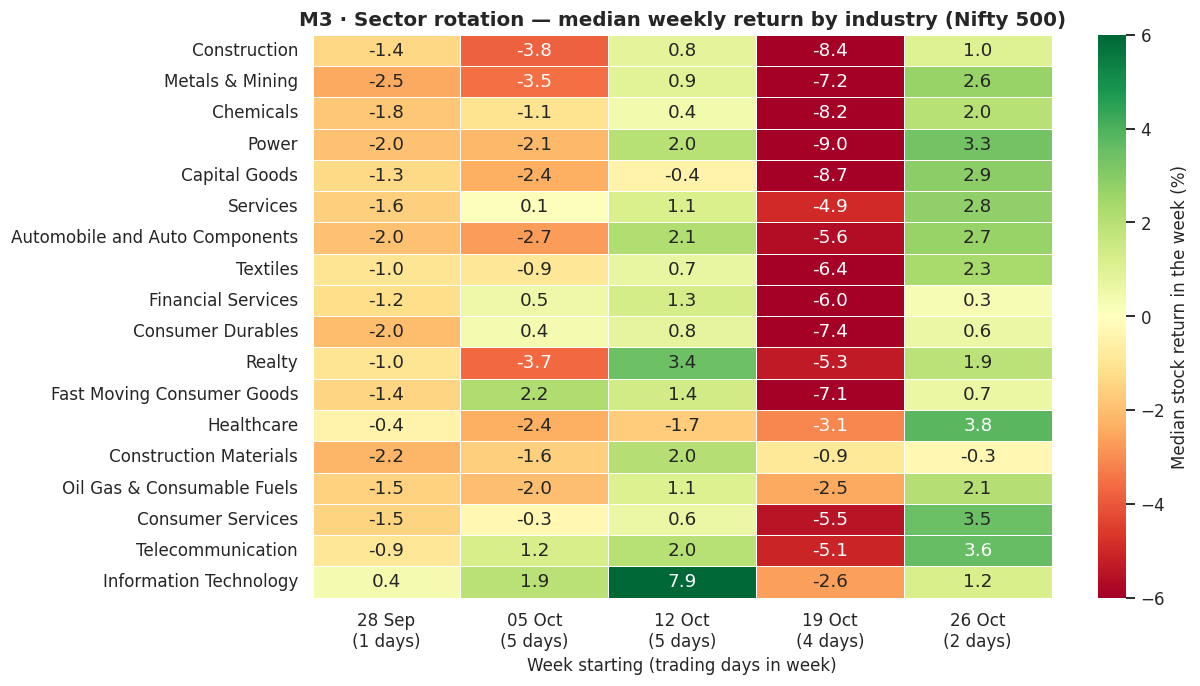

In [44]:
# M3 — Sector rotation: pivot table of weekly returns, industry × week
wk = (eq[eq["in_nifty500"] & eq["symbol"].isin(full.index)]
      .assign(lr=lambda d: np.log1p(d["ret_pct"].clip(-25, 25) / 100))
      .groupby(["symbol", "industry", "week_start"]).agg(lr=("lr", "sum"), days=("date", "nunique")).reset_index())
wk["wret"] = (np.exp(wk["lr"]) - 1) * 100
rot = wk[wk["industry"].isin(big)].pivot_table(index="industry", columns="week_start", values="wret", aggfunc="median")
days = wk.groupby("week_start")["days"].max()
rot.columns = [f"{c:%d %b}\n({days[c]} days)" for c in rot.columns]
rot = rot.loc[ind.sort_values("ret").index]
display(rot.round(1))

fig, ax = plt.subplots(figsize=(11.5, 6.4))
sns.heatmap(rot, annot=True, fmt=".1f", cmap="RdYlGn", center=0, vmin=-6, vmax=6, linewidths=.5, linecolor="white", cbar_kws={"label": "Median stock return in the week (%)"}, ax=ax)
ax.set_xlabel("Week starting (trading days in week)"); ax.set_ylabel("")
ax.set_title("M3 · Sector rotation — median weekly return by industry (Nifty 500)"); plt.tight_layout(); plt.show()

**Interpretation — M3 (pivot-table heatmap: `industry` × `week_start` → weekly return)**

**What it shows:** the median weekly return of Nifty 500 stocks in each industry. The first, one-day column (1 Oct) was negative for every industry except IT. The week of **12 Oct was a broad relief rally** (IT +7.9 %, Realty +3.4 %, Autos +2.1 %, Power +2.0 %; only Healthcare −1.7 % and Capital Goods −0.4 % fell). The week of **19 Oct (four sessions) was a sell-off** — every industry lost between 0.9 % and 9.0 %, led by Power (−9.0 %), Capital Goods (−8.7 %), Construction (−8.4 %) and Chemicals (−8.2 %) — and the last two sessions (26–27 Oct) rebounded across the board (−0.3 % to +3.8 %).

**Rotation:** in the sell-off week the defensives held up best — Construction Materials (−0.9 %), Oil & Gas (−2.5 %), IT (−2.6 %) and Healthcare (−3.1 %) — while cyclicals fell hardest. IT, up in the first session and in the weeks of 5 and 12 Oct, explains why it is the best-performing industry of the month.

**Takeaway:** most industry returns move with the market; the useful signal is *relative* strength, which a weekly heatmap makes visible.

---
### D. Business deep-dive — Nifty 500 vs the rest of the market

,stocks,median_deliv_pct,median_range_pct,median_daily_turnover_cr,median_return_pct,share_of_turnover_pct
group,,,,,,
Nifty 500,493,46.81,3.23,89.18,-5.06,73.48
Rest of main board,2183,55.07,4.52,1.66,-6.08,26.52


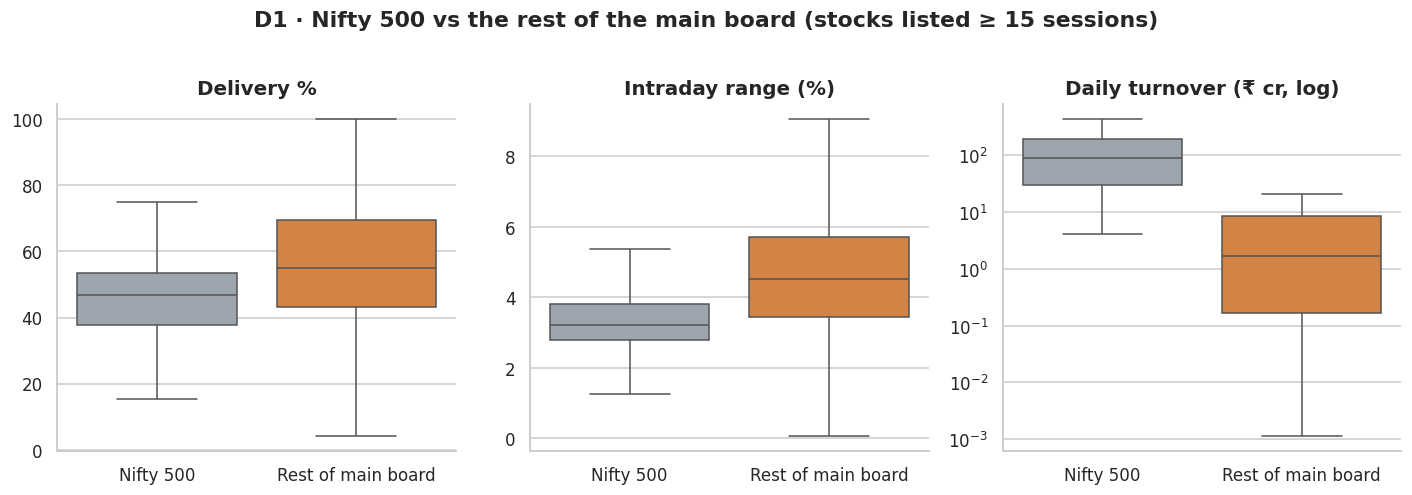

In [45]:
# D1 — Scorecard + chart: how does the Nifty 500 differ from everything else on the main board?
fm2 = fm.assign(group=np.where(fm["in_nifty500"], "Nifty 500", "Rest of main board"))
score = fm2.groupby("group").agg(stocks=("company", "size"), median_deliv_pct=("avg_deliv_pct", "median"), median_range_pct=("avg_range_pct", "median"),
                                  median_daily_turnover_cr=("avg_turnover_cr", "median"), median_return_pct=("cum_ret_pct", "median"),
                                  share_of_turnover_pct=("total_turnover_cr", lambda s: s.sum() / fm["total_turnover_cr"].sum() * 100))
display(score.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, (col, lab, log) in zip(axes, [("avg_deliv_pct", "Delivery %", False), ("avg_range_pct", "Intraday range (%)", False), ("avg_turnover_cr", "Daily turnover (₹ cr, log)", True)]):
    sns.boxplot(data=fm2, x="group", y=col, hue="group", palette=[ORANGE, GREY], order=["Nifty 500", "Rest of main board"], dodge=False, legend=False, showfliers=False, ax=ax)
    if log: ax.set_yscale("log")
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title(lab)
fig.suptitle("D1 · Nifty 500 vs the rest of the main board (stocks listed ≥ 15 sessions)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Interpretation — D1 (scorecard + three box plots by `in_nifty500`)**

**What it shows:** a scorecard and three box plots comparing the 493 Nifty 500 stocks with the 2,183 other main-board stocks (listed in at least 15 sessions). The Nifty 500 is **18 % of stocks but 73.5 % of turnover**; its median stock trades ₹89.2 crore a day versus ₹1.7 crore (54×) and each trade is almost 3× larger (₹20,107 vs ₹7,016). Its delivery % is *lower* (46.8 % vs 55.1 %), its intraday range *narrower* (3.2 % vs 4.5 %), and its median return slightly *better* (−5.1 % vs −6.1 %).

**Takeaway:** the index holds the liquid, institutional, heavily traded names — large intraday activity, small price swings. Outside it, a thin tail of small stocks has volatile prices and a higher delivery share (holders who cannot easily sell). Index-level conclusions cannot be applied to the rest of the market.

---
# Stage 4 — Documentation, Insights & Presentation

## 4.1 Summary of findings (plain English)
I cleaned and analysed **59,922 stock-day records — 17 NSE trading sessions (1–27 Oct 2026), 3,730 securities** — to see where genuine investor money flows.

- **October was a weak, jumpy month.** 57 % of stock-days were down, only 7 of 17 sessions had more advancers than decliners, and the median stock lost 6 %. Only IT (+10.5 %) and Telecom (+3.2 %) gained, and a sharp sell-off hit in the week of 19 Oct.
- **Trading is concentrated and mostly intraday.** 104 stocks carry half of all turnover, and on a typical liquid stock-day only about half of the shares traded are delivered (43 % by value).
- **Delivery went with selling, not buying.** Down-days had higher delivery than up-days (ρ = −0.12); the best days for prices were low-delivery days.
- **The Nifty 500 is a different market.** 18 % of stocks, 73.5 % of turnover, lower delivery and calmer prices.
- **No easy prediction.** Price, delivery, range and volume could not predict tomorrow's direction on unseen sessions (AUC 0.45–0.47).

## 4.2 Key insights
**1 · The market is really two markets.** Main-board shares are 72 % of securities but 98.7 % of turnover; the Nifty 500 is 18 % of main-board stocks yet 73.5 % of its turnover (median ₹89 crore a day vs ₹1.7 crore). Just 104 stocks carry half of everything traded, so market-wide averages describe a few hundred names.

**2 · Turnover is not conviction.** Delivery % falls as liquidity rises (ρ = −0.66) and as volatility rises (ρ = −0.40). PC Jeweller, one of the ten most traded stocks, had only 20 % delivery against HDFC Bank's 57 %.

**3 · In October, delivery went with falling prices.** Down-days had higher delivery than up-days (median 48.7 % vs 45.6 %; ρ = −0.12, p < 0.001), and the only band with a positive median return was the *speculative* one (+0.35 % vs −0.56 % for mixed days). Rallies were mostly intraday-driven; sell-offs were backed by real shares changing hands — investors exiting, not buying.

**4 · It was a weak and jumpy month.** Only 7 of 17 sessions had more advancers than decliners; breadth swung from 72 % (6 Oct) to 11 % (8 Oct) in two sessions, and on 8, 21 and 23 Oct close to nine in ten stocks fell in a single session. The median stock lost 6 % and 81 % of stocks ended lower.

**5 · Leadership rotated to IT and defensives.** IT gained 10.5 % (76 % of IT stocks rose; +7.9 % in the week of 12 Oct) and Telecom 3.2 %; in the sell-off week of 19 Oct cyclicals fell hardest (Power −9.0 %, Capital Goods −8.7 %) while Construction Materials, Oil & Gas, IT and Healthcare held up best.

**6 · Delivery % is not a tradable signal on its own.** After high-delivery days the next-day median return was −0.11 % vs −0.54 % after speculative days — detectable, but small — and models using delivery, price, range and turnover scored an AUC of 0.45–0.47 on unseen sessions (coin toss = 0.50). Conviction also does not explain industry performance (rank correlation −0.07).

## 4.3 Types of analysis

### 1 · Descriptive analysis — *what happened?*
Sections 3.1–3.3 and the univariate / daily charts: ₹1.14 lakh crore traded on a typical day, 98.7 % of it on the main board; median delivery of 48 % on liquid stock-days; a market that fell in 57 % of stock-days; 104 stocks carrying half of all turnover.

### 2 · Diagnostic analysis — *why did it happen?*
Section 3.4 and the bivariate / multivariate charts: delivery % *rises with falling prices* (ρ = −0.12), falls with liquidity (ρ = −0.66), differs by industry, and the Nifty 500 trades with *less* delivery but much *less* volatility than the rest of the market.

### 3 · Predictive analysis — *what is likely to happen?*
Test the obvious trading idea: *can today's price, delivery %, range, gap, turnover and price level predict whether a stock rises tomorrow?* The models are trained on the first 70 % of sessions and tested on the **last 30 % (unseen sessions)** — never on data they have seen.

In [46]:
mdl = liquid.dropna(subset=["ret_next"]).copy()
mdl = mdl[mdl["ret_next"].abs() <= 25]
mdl["log_turnover"] = np.log10(mdl["turnover_cr"])
mdl["log_price"]    = np.log10(mdl["close"])
mdl["y_up"]         = (mdl["ret_next"] > 0).astype(int)
feats = ["deliv_pct", "ret_pct", "range_pct", "gap_pct", "log_turnover", "log_price"]

cut = np.sort(mdl["date"].unique())[int(mdl["date"].nunique() * 0.7)]          # time-based split – no peeking into the future
train, test = mdl[mdl["date"] < cut], mdl[mdl["date"] >= cut]
print(f"Train: {len(train):,} stock-days ({train['date'].nunique()} sessions)  |  Test: {len(test):,} stock-days ({test['date'].nunique()} sessions, from {pd.Timestamp(cut):%d %b})")
print(f"Share of stocks that rose next day — train {train['y_up'].mean():.1%}, test {test['y_up'].mean():.1%}")

models = {
    "Baseline (always predict the majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=50, random_state=RANDOM_STATE, n_jobs=-1),
}
rows = []
for name, m_ in models.items():
    m_.fit(train[feats], train["y_up"])
    proba = m_.predict_proba(test[feats])[:, 1]
    rows.append({"model": name, "accuracy": accuracy_score(test["y_up"], m_.predict(test[feats])), "ROC AUC (0.50 = coin toss)": roc_auc_score(test["y_up"], proba)})
pd.DataFrame(rows).set_index("model")

Train: 17,901 stock-days (11 sessions)  |  Test: 8,298 stock-days (5 sessions, from 19 Oct)
Share of stocks that rose next day — train 46.1%, test 37.1%


,accuracy,ROC AUC (0.50 = coin toss)
model,,
Baseline (always predict the majority class),0.63,0.50
Logistic regression,0.55,0.45
Random forest,0.51,0.47


**Interpretation — predictive test**

**Result:** on unseen sessions the models have **no skill — they are slightly worse than a coin toss.** Predicting whether a stock rises tomorrow gives an **AUC of 0.45 (logistic regression) and 0.47 (random forest)**, where 0.50 is pure chance, and accuracy (55 % and 51 %) is below the 63 % baseline of always guessing "down" — in the test sessions (from 19 Oct) 63 % of stocks fell the next day, against 54 % in the training sessions.

**Takeaway:** the patterns in the first eleven sessions did not carry into the late-October sell-off. That is a useful *negative* result: it argues against trading rules built on delivery, price and volume alone, in line with T6 / T7, and shows how regime-dependent such signals are. Limits: only 11 training sessions and one market regime.

### 4 · Prescriptive analysis — *what should we do?*
Insight must change a decision. The function below turns the findings into a **stock-screening tool**: it ranks liquid **Nifty 500 companies** (the official list identifies real operating companies) by a *conviction score* — the average of three percentile ranks: **high delivery %**, **strong period return** and **low volatility**. It returns a short, explainable watch-list for an analyst to investigate — a starting point for research, not a buy recommendation.

In [47]:
def accumulation_screen(industry=None, min_turnover_cr=20, top=10):
    """Rank liquid Nifty 500 companies by conviction score (optionally within one industry)."""
    pool = full[full["in_nifty500"] & full["segment"].str.startswith("Main") & (full["avg_turnover_cr"] >= min_turnover_cr)]
    if industry:
        pool = pool[pool["industry"] == industry]
    pool = pool.copy()
    pool["score"] = (pool["avg_deliv_pct"].rank(pct=True) + pool["cum_ret_pct"].rank(pct=True) + (1 - pool["volatility_pct"].rank(pct=True))) / 3 * 100
    cols = ["company", "industry", "avg_deliv_pct", "cum_ret_pct", "volatility_pct", "avg_turnover_cr", "score"]
    return pool.sort_values("score", ascending=False)[cols].head(top).round(1), pool

shortlist, pool = accumulation_screen(min_turnover_cr=20, top=10)
print(f"Universe: {len(pool)} Nifty 500 companies trading ≥ ₹20 crore a day on average")
shortlist

Universe: 423 Nifty 500 companies trading ≥ ₹20 crore a day on average


,company,industry,avg_deliv_pct,cum_ret_pct,volatility_pct,avg_turnover_cr,score
symbol,,,,,,,
ONGC,Oil & Natural Gas Corporation Ltd.,Oil Gas & Consumable Fuels,65.70,1.80,1.00,249.80,93.20
STARHEALTH,Star Health and Allied Insurance Company Ltd.,Financial Services,65.20,2.30,1.30,23.10,92.00
KOTAKBANK,Kotak Mahindra Bank Ltd.,Financial Services,65.80,6.10,1.50,1206.80,91.90
BHARTIARTL,Bharti Airtel Ltd.,Telecommunication,67.30,12.60,1.60,1649.20,91.10
PETRONET,Petronet LNG Ltd.,Oil Gas & Consumable Fuels,60.50,4.00,1.40,70.10,90.90
ICICIBANK,ICICI Bank Ltd.,Financial Services,58.20,4.90,1.40,1767.90,90.10
INDUSTOWER,Indus Towers Ltd.,Telecommunication,61.20,3.20,1.50,182.80,89.90
MARICO,Marico Ltd.,Fast Moving Consumer Goods,62.30,-1.30,0.80,131.70,88.70
PIDILITIND,Pidilite Industries Ltd.,Chemicals,60.90,-1.00,1.30,90.20,86.80


In [48]:
# The same screen inside one industry – e.g. Capital Goods (engineering / industrial companies)
short_cg, pool_cg = accumulation_screen(industry="Capital Goods", min_turnover_cr=10, top=8)
print(f"Universe: {len(pool_cg)} Capital Goods companies trading ≥ ₹10 crore a day on average")
short_cg

Universe: 65 Capital Goods companies trading ≥ ₹10 crore a day on average


,company,industry,avg_deliv_pct,cum_ret_pct,volatility_pct,avg_turnover_cr,score
symbol,,,,,,,
HAL,Hindustan Aeronautics Ltd.,Capital Goods,51.00,4.00,1.80,343.80,90.80
ASTRAL,Astral Ltd.,Capital Goods,48.10,0.40,1.50,56.50,86.70
BEL,Bharat Electronics Ltd.,Capital Goods,55.10,-5.20,1.40,381.70,83.10
AIAENG,AIA Engineering Ltd.,Capital Goods,57.30,-7.10,1.30,14.70,82.60
CUMMINSIND,Cummins India Ltd.,Capital Goods,61.70,-4.80,2.00,212.70,81.00
USHAMART,Usha Martin Ltd.,Capital Goods,55.40,-3.90,2.10,28.00,81.00
TIMKEN,Timken India Ltd.,Capital Goods,61.70,-11.50,1.30,15.00,77.90
SHYAMMETL,Shyam Metalics and Energy Ltd.,Capital Goods,50.50,8.30,2.60,51.40,76.90


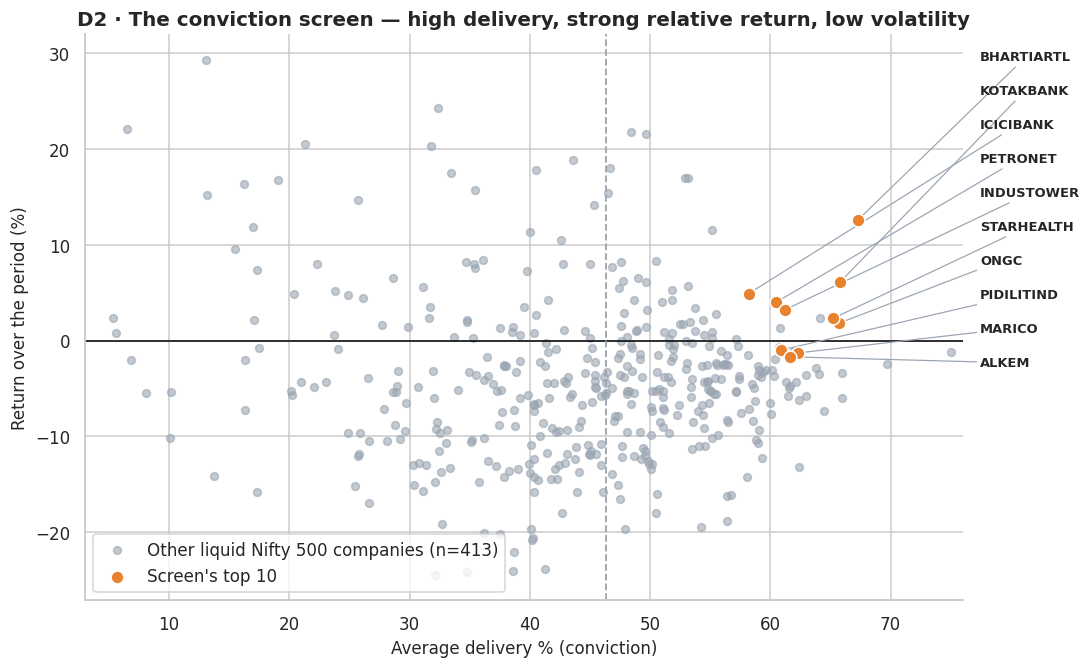

In [49]:
# D2 — the screen on a map: delivery % vs period return
fig, ax = plt.subplots(figsize=(10.5, 6.2))
ax.scatter(pool["avg_deliv_pct"], pool["cum_ret_pct"], s=26, color=GREY, alpha=0.6, label=f"Other liquid Nifty 500 companies (n={len(pool) - len(shortlist)})")
ax.scatter(shortlist["avg_deliv_pct"], shortlist["cum_ret_pct"], s=70, color=ORANGE, edgecolor="white", label="Screen's top 10", zorder=5)
# labels are stacked in a column on the right (ordered by return) with leader lines, so they can never collide
for rank, (sym, r) in enumerate(shortlist.sort_values("cum_ret_pct", ascending=False).iterrows()):
    ax.annotate(sym, xy=(r["avg_deliv_pct"], r["cum_ret_pct"]), xycoords="data", xytext=(1.02, 0.96 - rank * 0.06), textcoords="axes fraction",
                fontsize=8.5, fontweight="bold", va="center", annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8, shrinkA=0, shrinkB=3))
ax.axhline(0, color="black", lw=1); ax.axvline(pool["avg_deliv_pct"].median(), color=GREY, ls="--", lw=1.2)
ax.set_xlim(3, 76); ax.set_xlabel("Average delivery % (conviction)"); ax.set_ylabel("Return over the period (%)")
ax.set_title("D2 · The conviction screen — high delivery, strong relative return, low volatility"); ax.legend(loc="lower left")
fig.subplots_adjust(left=0.08, right=0.84, top=0.93, bottom=0.10); plt.show()

**Interpretation — screening tool**

**Nifty 500 screen (423 companies trading ≥ ₹20 crore a day):** the top ten are ONGC, Star Health, Kotak Mahindra Bank, Bharti Airtel, Petronet LNG, ICICI Bank, Indus Towers, Marico, Pidilite and Alkem — delivery 58–67 %, daily volatility 0.8–1.6 %, and period returns from −1.7 % to +12.6 % in a month when the median stock in the group lost 4.4 %. All ten beat that median. They are *defensive, well-held* names: the screen finds shares that investors kept through the sell-off. The 18 stocks with gains above 15 % had low delivery (median 34.4 %) and higher volatility (2.6 % vs 2.2 % a day), which the score penalises.

**Within Capital Goods (65 companies):** HAL (+4.0 %), Astral, BEL, AIA Engineering and Cummins India lead. The tool is deliberately explainable — every name can be traced back to three numbers.

**Why it matters:** it turns the analysis into a repeatable, auditable watch-list generator for an analyst. It is a research starting point, not investment advice.

## 4.4 Recommendations / decision support
1. **Read delivery % together with price direction.** Never treat high delivery as bullish by itself — in October it accompanied declines. Build alerts on the *combination* (falling price + rising delivery = distribution; rising price + rising delivery = accumulation).
2. **Track breadth, not just the index.** Publish advancers ÷ (advancers + decliners) daily: it swung from 72 % (6 Oct) to 11 % (8 Oct) in two sessions and shows fragility that headline prices hide.
3. **Separate the liquid core from the long tail.** SME and trade-for-trade securities are 23.6 % of the list but about 1 % of turnover, and trade-for-trade shares swing wider (median range 4.6 % vs 3.8 %). Treat them as liquidity-risk products with position limits and clear warnings.
4. **Add a weekly sector-rotation view.** The heatmap (M3) shows the defensive-versus-cyclical split in the sell-off week and IT's leadership; a weekly rotation report is more informative than daily price tables.
5. **Use the conviction screen as a research list, not a recommendation.** It produces auditable shortlists; pair them with fundamentals before acting, and do not rely on delivery % alone — the prediction test shows no edge.
6. **Automate with validation.** Raw exchange files need checks every day — holiday files re-served as new days, text-typed numbers, structural dashes. The cleaning stage of this notebook can become that daily check.

## 4.5 Limitations (what this analysis can and cannot say)
- **Short window, one regime.** 17 sessions (1–27 Oct 2026) in a broadly falling month; the last three sessions of October (28–30 Oct) had not been published when the data were collected. Patterns — especially delivery vs returns — may differ in a rising market.
- **Delivery % cannot tell buyers from sellers.** It measures shares delivered, which both sides take part in, so "conviction" is a proxy.
- **No instrument-type or market-cap column.** ETFs and liquid funds trade inside the main-board series (roughly 2.5 % of turnover by name), and company size can only be proxied by turnover.
- **Prices are not adjusted.** Splits, bonus issues and IPO listing days produce extreme one-day moves (22 beyond ±25 %), which are flagged and winsorised rather than corrected.
- **Industry labels exist only for the Nifty 500** (500 companies); the other 3,200+ securities are "Not in Nifty 500".
- **One exchange.** NSE only; trades that happen only on BSE are not included.
- **Rule-based fills.** 100 % delivery for trade-for-trade series follows the exchange's rule but is still an assumption about unpublished figures.

## 4.6 Future enhancements
- **Longer history** — extend the window from one month (17 sessions) to several months or years (the collection notebook only needs a wider date range) to separate a *bull-market* pattern from a *bear-market* one.
- **Fundamentals** — join market capitalisation, P/E and earnings so conviction can be compared with valuation.
- **Corporate-action adjustment** — adjust prices for splits and bonuses, and mark IPO listing days, so extreme moves are explained rather than flagged.
- **Dashboard** — publish the cleaned tables as an interactive Power BI / Tableau market-pulse dashboard (turnover, breadth, delivery %, sector heatmap).
- **Automation** — schedule the collection and cleaning steps to run after every trading day and e-mail the screen.

## 4.7 Conclusion
This project took the exchange's raw daily file — with delivery data hidden behind text dashes, bonds and funds mixed in with shares, extreme one-day moves and a dummy company in the official list — and turned it into a validated, 59,922-row analysis table, documenting every decision and flagging every fill.

The analysis shows that the Indian market in October 2026 was **narrow, concentrated and mostly intraday**: about a hundred stocks carry half the money, delivery is lowest where liquidity is highest, and delivery rose with falling prices rather than rising ones. The honest finding is also a negative one — delivery % and price action alone do not predict tomorrow's move.

The project closes with a decision tool (the conviction screen), prescriptive recommendations and a clear list of limitations — the combination of rigour, business framing and honesty that an analytics team values.

## Appendix — export the clean dataset
The cleaned stock-day table and the stock-level table can be reused, for example as the data sources of a Power BI / Tableau dashboard.

In [50]:
df.to_csv("nse_stock_days_clean.csv", index=False)
stock.reset_index().to_csv("nse_stock_level_summary.csv", index=False)
print(f"Saved nse_stock_days_clean.csv → {df.shape[0]:,} rows × {df.shape[1]} columns  |  nse_stock_level_summary.csv → {len(stock):,} rows")
# In Google Colab, uncomment to download:
# from google.colab import files
# files.download("nse_stock_days_clean.csv"); files.download("nse_stock_level_summary.csv")

Saved nse_stock_days_clean.csv → 59,922 rows × 34 columns  |  nse_stock_level_summary.csv → 3,560 rows
